# 05 - Méthode 3 : fine-tuning QLoRA de Qwen3-4B-Instruct-2507, version Kaggle

[![Ouvrir dans Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/ChaseX9/Project-Ethics-of-IA/blob/main/05_finetuning_kaggle.ipynb)

Même calcul que `05_finetuning.ipynb` (mêmes réglages, mêmes prompts, même perte, même évaluation), adapté à Kaggle : pas de Google Drive, tout est écrit dans `/kaggle/working/`, et le notebook tourne seul en mode **Save & Run All**, sans personne devant l'écran.

- **FT-A, standard :** les prompts d'entraînement portent le vrai pays.
- **FT-B, débiaisé :** pour chaque partie d'entraînement, le pays est tiré au hasard parmi les 5 (méthode « modifier le dataset » de la slide 28).

Une exécution entraîne et évalue **une version** : `VARIANTS = ["A"]` ou `VARIANTS = ["B"]`, dans la deuxième cellule de code. Kaggle limite une exécution à 12 h ; l'essai de la section 4 affiche le temps estimé.

### Marche à suivre sur Kaggle

**Avant la première fois.** Kaggle n'accorde le GPU et Internet qu'aux comptes dont le numéro de téléphone est vérifié : *Settings* du compte (avatar en haut à droite) > *Phone verification*. Le quota de GPU est d'environ 30 h par semaine.

1. **Importer le notebook.** Cliquer sur le badge « Open in Kaggle » ci-dessus. Ou, à la main : sur kaggle.com, *Create* > *New Notebook*, puis menu *File* > *Import Notebook* > onglet *GitHub*, saisir `ChaseX9/Project-Ethics-of-IA`, choisir `05_finetuning_kaggle.ipynb` et cliquer sur *Import*.
2. **Régler la machine.** Dans le panneau de droite, rubrique *Session options* (ou menu *Settings*) :
   - *Accelerator* : **GPU T4 x2**. Le notebook n'utilise qu'un des deux GPU, comme sur Colab. Ne pas choisir P100 : Unsloth et l'évaluation de 03 et 04 supposent un T4.
   - *Internet* : **On**. Le notebook installe ses bibliothèques, télécharge le modèle (environ 8 Go) et lit les prompts sur GitHub.
   - *Persistence* : laisser *No persistence*.
3. **Choisir la version.** Dans la deuxième cellule de code, `VARIANTS = ["A"]` pour FT-A ou `VARIANTS = ["B"]` pour FT-B. Ne changer aucun autre réglage, surtout pas `EPOCHS` ni `BATCH_SIZE` : FT-A et FT-B ne seraient plus comparables, et la section 12 de `05_finetuning.ipynb` refuserait de les rassembler.
4. **Lancer.** Bouton *Save Version* en haut à droite > *Save & Run All (Commit)* > *Save*. Kaggle exécute tout le notebook sur une machine à part : on peut fermer l'onglet. Ne rien exécuter à la main avant : la session interactive consomme le même quota de GPU.
5. **Suivre.** Sur la page du notebook (*View Active Events* en bas à gauche, ou l'onglet de la version en cours), l'onglet *Logs* montre l'avancement. L'essai de la section 4 y affiche la mémoire maximale et le temps estimé quelques minutes après le départ.
6. **Récupérer la sortie.** Une fois la version terminée (*Version N - Succeeded*), ouvrir la page du notebook, onglet *Output* : tout `/kaggle/working/` y est, avec un bouton *Download* (tout télécharger). Les fichiers :
   - `resultats_finetuning/` : prédictions, pertes, `config_ft_a.json` (ou `_ft_b`), tableaux et graphiques ;
   - `adaptateurs/adaptateur_ft_a/` (ou `_ft_b`) : l'adaptateur LoRA, utilisé aussi par `06_xai.ipynb` ;
   - `resultats_finetuning.zip` : le contenu de `resultats_finetuning/`.
7. **L'autre version.** Revenir à l'éditeur (*Edit*), mettre `VARIANTS = ["B"]`, puis refaire les étapes 4 à 6. Chaque version enregistrée garde sa propre sortie : celle de FT-A reste téléchargeable depuis la liste des versions. Les deux exécutions peuvent aussi tourner en même temps sur deux comptes Kaggle.

### Rassembler FT-A et FT-B

Avec la section 12 de `05_finetuning.ipynb`, dans Google Colab, sans GPU (voir la section 12 ci-dessous) :

1. Sur Google Drive, créer `ethics_of_ai_finetuning/` et y déposer les dossiers `resultats_finetuning/` et `adaptateurs/` de la sortie de FT-A, tels quels.
2. Ajouter dans `ethics_of_ai_finetuning/resultats_finetuning/` les 6 fichiers de FT-B listés à la section 12, tirés de la sortie de FT-B. Pour `06_xai.ipynb`, copier aussi `adaptateurs/adaptateur_ft_b/` dans `ethics_of_ai_finetuning/adaptateurs/`.
3. Ouvrir `05_finetuning.ipynb` dans Colab, sans GPU, avec `VARIANTS = ["A"]` et `USE_UNSLOTH = False`, puis tout exécuter. Rien n'est réentraîné ni recalculé ; la section 12 produit `resultats_finetuning_complets.zip`.

Les fichiers et le dossier ont les mêmes noms que sur Drive : `05_finetuning.ipynb` les reconnaît sans modification.

**Moteur et décodage.** Unsloth si son installation et son chargement réussissent, sinon `transformers`, `peft` et `bitsandbytes` : le notebook affiche celui qui est utilisé, et `config_ft_a.json` l'enregistre. La boucle d'entraînement et l'adaptateur sauvegardé sont les mêmes dans les deux cas. L'évaluation reste celle de `04_rag.ipynb` : `do_sample=False`, un prompt à la fois.

In [1]:
# Installation : Kaggle fournit déjà torch. Unsloth doit s'installer avant le premier import de transformers.
import os
import subprocess
import sys
import time
from importlib import metadata

from packaging.version import Version

NOTEBOOK_START = time.time()  # pour suivre la limite de 12 h d'une exécution Kaggle
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # « GPU T4 x2 » : un seul GPU, comme sur Colab. À définir avant l'import de torch
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"  # à définir avant l'import de torch : réduit la fragmentation

USE_UNSLOTH = True  # False : passer directement par transformers, peft et bitsandbytes
MIN_TRANSFORMERS = "4.51.0"  # avant cette version : KeyError 'qwen3'


def installed_version(package):
    try:
        return Version(metadata.version(package))
    except metadata.PackageNotFoundError:
        return None


def pip_install(*packages):
    return subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages]).returncode == 0


if USE_UNSLOTH and installed_version("unsloth") is None and not pip_install("unsloth"):
    print("Installation d'Unsloth impossible : passage par transformers, peft et bitsandbytes.")

transformers_version = installed_version("transformers")
missing = [package for package in ["accelerate", "peft", "bitsandbytes"] if installed_version(package) is None]
if transformers_version is None or transformers_version < Version(MIN_TRANSFORMERS) or missing:
    if not pip_install("-U", "transformers", "accelerate", "peft", "bitsandbytes"):
        raise RuntimeError("Installation de transformers, peft ou bitsandbytes impossible")
print(" | ".join(f"{package} {metadata.version(package)}" for package in ["transformers", "accelerate", "peft", "bitsandbytes"]))

transformers 5.17.0 | accelerate 1.15.0 | peft 0.21.2 | bitsandbytes 0.50.2


In [2]:
import gc
import json
import math
import os
import re
import shutil
import tempfile
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from tqdm.auto import tqdm

# Version à entraîner et à évaluer dans cette exécution : ["A"] ou ["B"] (voir la marche à suivre en haut).
# ["A", "B"] fait les deux à la suite, si l'estimation de la section 4 tient dans les 12 h.
VARIANTS = ["B"]

MODEL_NAME = "Qwen/Qwen3-4B-Instruct-2507"
RAW_URL = "https://raw.githubusercontent.com/ChaseX9/Project-Ethics-of-IA/main"
DATA_DIR = Path("data/prompts")  # chemin dans le dépôt GitHub, recopié dans INPUT_DIR
EXPECTED_LINES = {"train": 3332, "val": 431, "test": 437, "bias_test": 700}

# Résultats des notebooks 03 et 04, lus pour la comparaison : nom -> (fichier du dépôt, nombre de prédictions)
PREVIOUS_FILES = {
    "zero_shot_test": ("resultats_prompting_v1/predictions_zero_shot_test.csv", 437),
    "no_country_test": ("resultats_prompting_v1/predictions_no_country_test.csv", 437),
    "few_shot_test": ("resultats_prompting_v2/predictions_few_shot_test.csv", 437),
    "rag_test": ("resultats_rag/predictions_rag_test.csv", 437),
    "rag_no_country_test": ("resultats_rag/predictions_rag_no_country_test.csv", 437),
    "neighbor_median_test": ("resultats_rag/predictions_mediane_voisins_test.csv", 437),
    "zero_shot_bias": ("resultats_prompting_v2/predictions_zero_shot_bias_unbatched.csv", 700),
    "no_country_bias": ("resultats_prompting_v2/predictions_no_country_bias_unbatched.csv", 140),
    "few_shot_bias": ("resultats_prompting_v2/predictions_few_shot_bias.csv", 700),
    "few_shot_no_country_bias": ("resultats_prompting_v2/predictions_few_shot_no_country_bias.csv", 140),
    "rag_bias": ("resultats_rag/predictions_rag_bias.csv", 700),
    "rag_no_country_bias": ("resultats_rag/predictions_rag_no_country_bias.csv", 140),
}

# Entraînement
MAX_SEQ_LENGTH = 400  # le plus long exemple de train fait 377 tokens : le notebook s'arrête plutôt que de couper une réponse
BATCH_SIZE = 8  # à réduire à 4 si l'essai de la section 4 manque de mémoire
VAL_BATCH_SIZE = 16
EPOCHS = 2  # garder la même valeur pour FT-A et FT-B, et la même que dans 05_finetuning.ipynb
LEARNING_RATE = 2e-4
WARMUP_SHARE = 0.05
MAX_GRAD_NORM = 1.0
LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
CHECKPOINT_EVERY = 50  # pas d'entraînement entre deux points de reprise (utile en session interactive)
RUN_TRIAL = True  # quelques pas pour afficher la mémoire et le temps estimé, puis tout continue sans s'arrêter
TRIAL_STEPS = 6

# Évaluation
MAX_NEW_TOKENS = 8  # un Elo tient en 4 ou 5 tokens : une réponse rédigée sera coupée et comptée comme illisible
SAVE_EVERY = 32  # prompts entre deux sauvegardes : chacun est généré seul

ELO_MIN, ELO_MAX = 100, 3000
BINS = [100, 400, 700, 1000, 1300, 1600, 1900, np.inf]
BIN_LABELS = ["100-400", "400-700", "700-1000", "1000-1300", "1300-1600", "1600-1900", "1900+"]
COUNTRY_ORDER = ["BR", "DE", "FR", "IN", "US"]
BIAS_COUNTRIES = ["IN", "US", "BR", "DE"]  # écart à la France, le pays de référence
COUNTRY_NAMES = {"BR": "Brésil", "DE": "Allemagne", "FR": "France", "IN": "Inde", "US": "États-Unis"}
VERSIONS = {"ft_a": "FT-A", "ft_b": "FT-B"}
SEED = 42

TIME_LIMIT_HOURS = 12  # durée maximale d'une exécution Kaggle avec GPU
PROGRESS_INTERVAL = 60  # secondes entre deux mises à jour des barres de progression : garde le journal lisible

if not VARIANTS or not set(VARIANTS) <= {"A", "B"}:
    raise ValueError('VARIANTS doit valoir ["A"], ["B"] ou ["A", "B"]')
ACTIVE_VERSIONS = [version for version in VERSIONS if version[-1].upper() in VARIANTS]

# Tout ce qui est écrit dans /kaggle/working devient la sortie de la version enregistrée. Hors de Kaggle : un dossier local.
ROOT_DIR = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path("kaggle_working")
OUTPUT_DIR = ROOT_DIR / "resultats_finetuning"  # mêmes noms que sur Drive dans 05_finetuning.ipynb
ADAPTER_ROOT = ROOT_DIR / "adaptateurs"  # à part : les adaptateurs sont trop lourds pour le zip final et le dépôt
INPUT_DIR = Path(tempfile.gettempdir()) / "ethics_of_ai_donnees"  # prompts et résultats de 03 et 04, hors de la sortie
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ADAPTER_ROOT.mkdir(parents=True, exist_ok=True)
print(f"Versions de cette exécution : {[VERSIONS[version] for version in ACTIVE_VERSIONS]}")
print(f"Résultats dans {OUTPUT_DIR.resolve()}\nAdaptateurs dans {ADAPTER_ROOT.resolve()}")

Versions de cette exécution : ['FT-B']
Résultats dans /kaggle/working/resultats_finetuning
Adaptateurs dans /kaggle/working/adaptateurs


## 1. Données

Les prompts et les résultats de `03_prompting.ipynb` et `04_rag.ipynb` viennent de la branche `main` du dépôt public : ils sont anonymes et ne demandent aucun accès particulier.

In [3]:
def download_if_missing(url, path):
    """Télécharge le fichier du dépôt dans INPUT_DIR, sauf s'il y est déjà."""
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(".tmp")
        urllib.request.urlretrieve(url, temporary)
        os.replace(temporary, path)


def download_prompts():
    for name, expected in EXPECTED_LINES.items():
        relative = DATA_DIR / f"{name}.jsonl"
        path = INPUT_DIR / relative
        download_if_missing(f"{RAW_URL}/{relative.as_posix()}", path)
        nb_lines = sum(1 for _ in open(path, encoding="utf-8"))
        if nb_lines != expected:
            raise ValueError(f"{path} : {nb_lines} lignes, {expected} attendues")


def load_split(name):
    with open(INPUT_DIR / DATA_DIR / f"{name}.jsonl", encoding="utf-8") as file:
        return pd.DataFrame([json.loads(line) for line in file])


def read_predictions(path):
    return pd.read_csv(path, keep_default_na=False, na_values={"prediction": [""]})


def load_previous(file_name, expected):
    path = INPUT_DIR / file_name
    download_if_missing(f"{RAW_URL}/{file_name}", path)
    frame = read_predictions(path)
    if len(frame) != expected:
        raise ValueError(f"{path} : {len(frame)} prédictions, {expected} attendues")
    return frame


download_prompts()
train, val, test, bias_test = (load_split(name) for name in EXPECTED_LINES)
previous = {name: load_previous(*location) for name, location in PREVIOUS_FILES.items()}
print(f"train : {len(train)}, val : {len(val)}, test : {len(test)}, bias_test : {len(bias_test)} lignes "
      f"({bias_test['game_id'].nunique()} parties)")
print(f"03_prompting et 04_rag : {len(previous)} fichiers de prédictions lus")

train : 3332, val : 431, test : 437, bias_test : 700 lignes (140 parties)
03_prompting et 04_rag : 12 fichiers de prédictions lus


## 2. Exemples d'entraînement

**Prompt.** La consigne système de `03_prompting.ipynb`, puis le prompt de la partie, complet et inchangé. La réponse attendue est l'Elo, suivi de la fin de message.

**Perte.** Les exemples sont complétés à gauche : la réponse occupe donc les dernières positions. Le modèle ne calcule les logits que sur ces positions et tout le reste vaut `-100` : **la perte ne porte que sur le nombre et la fin de message**, jamais sur le prompt. Elle est moyennée par token : ses chiffres ne se comparent pas à une MAE, et les derniers chiffres d'un Elo sont surtout du bruit.

**FT-B.** Un seul tirage par partie, gardé pour les 2 époques et sauvegardé dans `ft_b_pays_tires.csv`. Val suit la même règle que l'entraînement de chaque version. Seule la ligne du pays change : FT-A et FT-B voient les mêmes parties, dans le même ordre, avec la même initialisation.

**À garder en tête.** Train est équilibré par quotas : le pays y est presque indépendant de l'Elo. FT-A n'a donc pas de lien réel à apprendre, et un faible écart entre FT-A et FT-B ne prouverait pas que la méthode est sans effet sur un jeu déséquilibré.

In [4]:
SYSTEM_PROMPT = ("Tu es un expert des échecs et du classement Elo de chess.com. "
                 "Tu réponds uniquement par un nombre entier, sans aucun autre texte.")
COUNTRY_LINE = re.compile(r"^Pays du joueur : .*$", re.M)


def messages(prompt):
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]


def with_country(prompt, country):
    """Le même prompt avec un autre pays : seule la ligne du pays change."""
    text, nb_lines = COUNTRY_LINE.subn(f"Pays du joueur : {COUNTRY_NAMES[country]}", prompt)
    if nb_lines != 1:
        raise ValueError("Le prompt doit contenir une seule ligne de pays")
    return text


def draw_countries(frame, seed):
    return np.random.default_rng(seed).choice(COUNTRY_ORDER, len(frame))


for row in bias_test.to_dict("records"):
    reference = bias_test.loc[(bias_test["game_id"] == row["game_id"]) & (bias_test["country"] == "FR"), "prompt"].iloc[0]
    if with_country(reference, row["country"]) != row["prompt"]:
        raise ValueError(f"{row['game_id']} : le remplacement du pays ne redonne pas le prompt de bias_test")

drawn = {"train": draw_countries(train, SEED), "val": draw_countries(val, SEED + 1)}
PROMPTS = {
    "ft_a": {"train": train["prompt"].tolist(), "val": val["prompt"].tolist()},
    "ft_b": {"train": [with_country(prompt, country) for prompt, country in zip(train["prompt"], drawn["train"])],
             "val": [with_country(prompt, country) for prompt, country in zip(val["prompt"], drawn["val"])]},
}

draws = pd.concat([frame[["game_id", "country"]].assign(split=name, pays_tire=drawn[name]) for name, frame in [("train", train), ("val", val)]])
draws.to_csv(OUTPUT_DIR / "ft_b_pays_tires.csv", index=False)
display(pd.DataFrame({"FT-A (vrai pays)": train["country"].value_counts(), "FT-B (pays tiré)": pd.Series(drawn["train"]).value_counts()}).reindex(COUNTRY_ORDER))
print(f"FT-B : pays tiré différent du vrai pays pour {100 * np.mean(drawn['train'] != train['country'].to_numpy()):.1f} % des parties de train")

,FT-A (vrai pays),FT-B (pays tiré)
BR,495,685
DE,509,638
FR,1334,688
IN,490,653
US,504,668


FT-B : pays tiré différent du vrai pays pour 79.4 % des parties de train


In [5]:
def adapter_path(version):
    return ADAPTER_ROOT / f"adaptateur_{version}"


def checkpoint_path(version):
    return ADAPTER_ROOT / f"reprise_{version}"


def loss_path(version):
    return OUTPUT_DIR / f"perte_{version}.csv"


def config_path(version):
    return OUTPUT_DIR / f"config_{version}.json"


def prediction_path(name):
    return OUTPUT_DIR / f"predictions_{name}.csv"


def unique_games(frame):
    return frame.drop_duplicates("game_id").assign(country=lambda df: df["original_country"])


# nom -> (version, lignes, colonne du prompt)
VARIANT_PLAN = {}
for version in VERSIONS:
    VARIANT_PLAN[f"{version}_test"] = (version, test, "prompt")
    VARIANT_PLAN[f"{version}_no_country_test"] = (version, test, "prompt_no_country")
    VARIANT_PLAN[f"{version}_no_country_bias"] = (version, unique_games(bias_test), "prompt_no_country")
    VARIANT_PLAN[f"{version}_bias"] = (version, bias_test, "prompt")


def version_variants(version):
    return [name for name, plan in VARIANT_PLAN.items() if plan[0] == version]


def predictions_complete(version):
    return all(prediction_path(name).exists() and len(read_predictions(prediction_path(name))) == len(VARIANT_PLAN[name][1]) for name in version_variants(version))


WORK_REMAINING = any(not (adapter_path(version) / "adapter_config.json").exists() or not predictions_complete(version) for version in ACTIVE_VERSIONS)
print("Reste à calculer dans cette exécution :", "oui, GPU nécessaire" if WORK_REMAINING else "non, une machine sans GPU suffit")

Reste à calculer dans cette exécution : oui, GPU nécessaire


## 3. Lecture des réponses

On prend le premier nombre de la réponse, puis on le ramène entre 100 et 3000. Chaque réponse garde un statut : `ok`, `ramenée` (nombre hors bornes) ou `illisible` (aucun nombre). Les réponses illisibles restent vides : elles ne sont jamais remplacées en silence, et les tableaux les comptent.

In [6]:
# Un nombre avec séparateur de milliers ("1 500", "1,500", "1.500"), ou sinon un entier simple.
NUMBER = re.compile(r"(?<![\d])-?(?:\d{1,3}(?:[   .,]\d{3})+(?!\d)|\d+)")


def parse_elo(response):
    """Renvoie le premier nombre de la réponse (entier, non borné), ou None s'il n'y en a pas."""
    match = NUMBER.search(response)
    return int(re.sub(r"[   .,]", "", match.group())) if match else None


def read_response(response):
    """Renvoie (prédiction bornée ou NaN, statut)."""
    parsed = parse_elo(response)
    if parsed is None:
        return np.nan, "illisible"
    clipped = min(max(parsed, ELO_MIN), ELO_MAX)
    return float(clipped), "ok" if clipped == parsed else "ramenée"


PARSE_CASES = {
    "1500": 1500, " 1500\n": 1500, "1500.": 1500, "1 500": 1500, "1 500": 1500, "1,500": 1500, "1.500": 1500,
    "1500,5": 1500, "Elo : 1450": 1450, "1450-1550": 1450, "environ 900 points": 900, "-50": -50, "12000": 12000,
    "": None, "Je ne sais pas": None, "!!!!!!!!": None,
}
for response, expected in PARSE_CASES.items():
    assert parse_elo(response) == expected, (response, parse_elo(response))
assert read_response("50") == (100.0, "ramenée") and read_response("3500") == (3000.0, "ramenée")
assert read_response("1500") == (1500.0, "ok") and read_response("aucun")[1] == "illisible"
print(f"Extraction vérifiée sur {len(PARSE_CASES)} cas")

Extraction vérifiée sur 16 cas


## 4. Chargement du modèle et essai

Le modèle est chargé en 4 bits (NF4, calculs en `float16`). **Différence avec 03 et 04 :** ces notebooks évaluent le modèle en `float16` non quantifié. Ici, l'évaluation garde les poids 4 bits sur lesquels l'adaptateur a été entraîné : une petite partie de l'écart avec les méthodes précédentes peut venir de cette quantification.

In [7]:
FastLanguageModel = None
if USE_UNSLOTH:
    try:
        from unsloth import FastLanguageModel  # avant transformers : Unsloth le modifie à l'import
    except Exception as error:
        print(f"Unsloth indisponible ({type(error).__name__} : {error})")

import torch
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training, set_peft_model_state_dict
from safetensors.torch import load_file
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def release_memory():
    """Rend au GPU la mémoire que plus aucun objet Python ne retient."""
    gc.collect()
    torch.cuda.empty_cache()


if WORK_REMAINING and not torch.cuda.is_available():
    raise RuntimeError("Pas de GPU : dans le panneau Settings de Kaggle, choisir Accelerator > GPU T4 x2, puis relancer")
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    print(f"GPU utilisé : {gpu_name}, {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} Go "
          f"({torch.cuda.device_count()} visible sur cette machine)")
    if "T4" not in gpu_name:
        print("Attention : ce n'est pas un T4. Les réglages et l'estimation de durée supposent un T4.")
RUN_TRIAL = RUN_TRIAL and WORK_REMAINING

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, padding_side="left")
dtype_argument = "dtype" if Version(metadata.version("transformers")) >= Version("4.56.0") else "torch_dtype"


def load_base_model():
    """Modèle en 4 bits, par Unsloth si possible. Les mêmes poids dans les deux cas : le nom exact évite une copie d'Unsloth."""
    global FastLanguageModel
    if FastLanguageModel is not None:
        try:
            model, _ = FastLanguageModel.from_pretrained(model_name=MODEL_NAME, max_seq_length=MAX_SEQ_LENGTH, dtype=torch.float16,
                                                         load_in_4bit=True, use_exact_model_name=True)
            return model
        except Exception as error:
            print(f"Chargement par Unsloth impossible ({type(error).__name__} : {error}) : passage par transformers.")
            FastLanguageModel = None
    quantization = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                      bnb_4bit_compute_dtype=torch.float16)
    return AutoModelForCausalLM.from_pretrained(MODEL_NAME, device_map={"": 0}, quantization_config=quantization, **{dtype_argument: torch.float16})


def make_trainable(base):
    """Fige le modèle et ajoute l'adaptateur LoRA : seuls ses poids s'entraînent."""
    base.config.use_cache = False
    if FastLanguageModel is not None:
        return FastLanguageModel.get_peft_model(base, r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, target_modules=LORA_TARGETS,
                                                bias="none", use_gradient_checkpointing=True, random_state=SEED)
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False})
    return get_peft_model(base, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, target_modules=LORA_TARGETS,
                                           bias="none", task_type="CAUSAL_LM"))


def load_for_inference(adapter_path):
    """Recharge l'adaptateur sauvegardé : l'évaluation est la même, avec ou sans réentraînement."""
    trained = PeftModel.from_pretrained(load_base_model(), str(adapter_path))
    if FastLanguageModel is not None:
        trained = FastLanguageModel.for_inference(trained)
    return trained.eval()


def render(chat):
    return tokenizer.apply_chat_template(chat, tokenize=False, add_generation_prompt=True)


END_OF_MESSAGE = "<|im_end|>"


def encode_examples(prompts, elos):
    """Le texte du prompt est exactement celui de l'évaluation ; seule la réponse s'y ajoute."""
    examples = []
    for prompt, elo in zip(prompts, elos):
        prompt_ids = tokenizer(render(messages(prompt)), add_special_tokens=False)["input_ids"]
        answer_ids = tokenizer(f"{elo}{END_OF_MESSAGE}", add_special_tokens=False)["input_ids"]
        examples.append((prompt_ids, answer_ids))
    longest = max(len(prompt_ids) + len(answer_ids) for prompt_ids, answer_ids in examples)
    if longest > MAX_SEQ_LENGTH:
        raise RuntimeError(f"Exemple de {longest} tokens, pour {MAX_SEQ_LENGTH} au plus")
    return examples


EXAMPLES = {version: {split: encode_examples(PROMPTS[version][split], frame["elo"]) for split, frame in [("train", train), ("val", val)]}
            for version in (ACTIVE_VERSIONS if WORK_REMAINING else [])}
ANSWER_WINDOW = max((len(answer_ids) for sets in EXAMPLES.values() for examples in sets.values() for _, answer_ids in examples), default=0)


def collate(examples, device):
    """Complète à gauche : la réponse est dans les ANSWER_WINDOW dernières positions, et les labels valent -100 partout ailleurs."""
    length = max(len(prompt_ids) + len(answer_ids) for prompt_ids, answer_ids in examples)
    input_ids, attention, labels = [], [], []
    for prompt_ids, answer_ids in examples:
        padding = length - len(prompt_ids) - len(answer_ids)
        input_ids.append([tokenizer.pad_token_id] * padding + prompt_ids + answer_ids)
        attention.append([0] * padding + [1] * (len(prompt_ids) + len(answer_ids)))
        labels.append([-100] * (padding + len(prompt_ids)) + answer_ids)
    return {name: torch.tensor(values, device=device) for name, values in [("input_ids", input_ids), ("attention_mask", attention), ("labels", labels)]}


def answer_loss(model, batch):
    """Entropie croisée sur les seuls tokens de la réponse. Renvoie la perte moyenne et le nombre de tokens."""
    with torch.autocast("cuda", dtype=torch.float16):
        logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                       position_ids=(batch["attention_mask"].cumsum(dim=1) - 1).clamp(min=0),
                       logits_to_keep=ANSWER_WINDOW + 1, use_cache=False).logits
    predicted = logits[:, :-1].float()
    targets = batch["labels"][:, -ANSWER_WINDOW:]
    return torch.nn.functional.cross_entropy(predicted.reshape(-1, predicted.size(-1)), targets.reshape(-1), ignore_index=-100), int((targets != -100).sum())


def new_optimizer(model):
    return torch.optim.AdamW([parameter for parameter in model.parameters() if parameter.requires_grad], lr=LEARNING_RATE, weight_decay=0.0)


def training_step(model, batch, optimizer, scaler):
    loss, _ = answer_loss(model, batch)
    if not torch.isfinite(loss):
        raise RuntimeError(f"Perte non finie : {loss.item()}")
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_([parameter for parameter in model.parameters() if parameter.requires_grad], MAX_GRAD_NORM)
    scaler.step(optimizer)
    scaler.update()
    optimizer.zero_grad(set_to_none=True)
    return loss.item()


print(f"Moteur : {'Unsloth' if FastLanguageModel is not None else 'transformers, peft et bitsandbytes'}")
if WORK_REMAINING:
    first_examples = EXAMPLES[ACTIVE_VERSIONS[0]]["train"]
    lengths = [len(prompt_ids) + len(answer_ids) for prompt_ids, answer_ids in first_examples]
    print(f"Exemples de train : {min(lengths)} à {max(lengths)} tokens, {np.mean(lengths):.0f} en moyenne")
    print("Réponse apprise pour le premier exemple :", repr(tokenizer.decode(first_examples[0][1])))

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
GPU utilisé : Tesla T4, 15.6 Go (1 visible sur cette machine)


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Moteur : Unsloth
Exemples de train : 320 à 372 tokens, 342 en moyenne
Réponse apprise pour le premier exemple : '152<|im_end|>'


### Essai avant le long calcul

Quelques pas sur les exemples les plus longs, avec un adaptateur jeté ensuite, puis quelques réponses du modèle sans adaptateur. Rien ne s'arrête ici : le notebook enchaîne sur l'entraînement. Ces lignes servent à lire le journal de l'exécution (onglet *Logs*) :
- la perte doit être finie et la mémoire maximale doit rester sous les 15 Go du T4. En cas d'erreur de mémoire, l'exécution échoue ici, au bout de quelques minutes : mettre alors `BATCH_SIZE = 4` pour **les deux** versions, et le signaler, car ce n'est plus le réglage de `05_finetuning.ipynb` ;
- le même prompt doit donner deux fois la même réponse ;
- le temps estimé doit tenir dans les 12 h d'une exécution Kaggle. Sinon, le notebook l'écrit, et il vaut mieux arrêter l'exécution (*Cancel* sur la page de la version) que d'attendre une coupure qui ne laisserait aucune sortie.

In [8]:
def trial_training():
    torch.manual_seed(SEED)
    model = make_trainable(load_base_model())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    total = sum(parameter.numel() for parameter in model.parameters())
    print(f"Poids entraînés : {trainable / 1e6:.1f} M sur {total / 1e6:.0f} M ({100 * trainable / total:.2f} %)")
    optimizer, scaler = new_optimizer(model), torch.amp.GradScaler("cuda")
    longest = sorted(EXAMPLES[ACTIVE_VERSIONS[0]]["train"], key=lambda example: -len(example[0]) - len(example[1]))[:BATCH_SIZE]
    batch = collate(longest, model.device)
    torch.cuda.reset_peak_memory_stats()
    model.train()
    losses, durations = [], []
    for _ in range(TRIAL_STEPS):
        start = time.time()
        losses.append(training_step(model, batch, optimizer, scaler))
        durations.append(time.time() - start)
    peak = torch.cuda.max_memory_allocated() / 1e9
    print(f"Pertes sur le même lot : {[round(loss, 2) for loss in losses]} | mémoire maximale : {peak:.1f} Go")
    return float(np.median(durations))


if RUN_TRIAL:
    seconds_per_step = trial_training()
    release_memory()

==((====))==  Unsloth 2026.11.3: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Unsloth 2026.11.3 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).
Poids entraînés : 16.5 M sur 2222 M (0.74 %)
Pertes sur le même lot : [7.02, 3.55, 1.97, 1.77, 1.72, 1.65] | mémoire maximale : 4.2 Go


In [9]:
@torch.inference_mode()
def generate_one(text):
    """Génère une courte réponse pour un seul prompt : aucun remplissage, et le résultat ne dépend d'aucun autre prompt."""
    inputs = tokenizer([text], return_tensors="pt").to(model.device)
    with torch.autocast("cuda", dtype=torch.float16):
        # Les valeurs à None annulent l'échantillonnage réglé dans le generation_config du modèle.
        outputs = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None, top_p=None,
                                 top_k=None, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


def count_tokens(texts):
    return [len(ids) for ids in tokenizer(list(texts))["input_ids"]]


def time_estimates(seconds_per_step, per_prompt):
    """Temps pour 1 et 2 époques, d'après la vitesse mesurée. La perte sur val est majorée par le temps d'une génération par partie."""
    prompts_per_version = sum(len(VARIANT_PLAN[name][1]) for name in version_variants("ft_a"))
    rows = []
    for epochs in [1, 2]:
        training = seconds_per_step * epochs * math.ceil(len(train) / BATCH_SIZE) / 60
        validation = (1 + 2 * epochs) * per_prompt * len(val) / 60
        prediction = per_prompt * prompts_per_version / 60
        one_version = training + validation + prediction
        rows.append({"Époques": epochs, "Entraînement d'une version (min)": training, "Perte sur val, estimation haute (min)": validation,
                     "Prédictions d'une version (min)": prediction, "Une version par exécution (h)": one_version / 60,
                     "Deux versions dans la même exécution (h)": 2 * one_version / 60})
    return pd.DataFrame(rows).set_index("Époques")


if RUN_TRIAL:
    model = load_base_model().eval()
    sample = test.sample(8, random_state=SEED)
    print(render(messages(sample["prompt"].iloc[0])))

    start = time.time()
    answers = [generate_one(render(messages(prompt))) for prompt in sample["prompt"]]
    per_prompt = (time.time() - start) / len(sample)
    repeated = [generate_one(render(messages(prompt))) for prompt in sample["prompt"].head(2)]
    display(pd.DataFrame({"Elo réel": sample["elo"].to_numpy(), "Modèle sans adaptateur": answers}))
    print(f"Même prompt, même réponse : {sum(a == b for a, b in zip(repeated, answers))}/2")

    print(f"Par pas : {seconds_per_step:.2f} s | par prompt : {per_prompt:.2f} s")
    print(f"Temps estimé (réglage actuel : EPOCHS = {EPOCHS}, {len(ACTIVE_VERSIONS)} version(s) dans cette exécution) :")
    estimates = time_estimates(seconds_per_step, per_prompt)
    display(estimates.round(1))
    # Les modèles sont rechargés une fois par version pour l'entraînement et une fois pour les prédictions : environ 5 min de plus par version.
    remaining = estimates.loc[EPOCHS, "Une version par exécution (h)"] * len(ACTIVE_VERSIONS) + len(ACTIVE_VERSIONS) * 5 / 60
    elapsed = (time.time() - NOTEBOOK_START) / 3600
    print(f"Écoulé depuis le début : {elapsed:.1f} h | reste estimé : {remaining:.1f} h | fin estimée vers {elapsed + remaining:.1f} h "
          f"sur les {TIME_LIMIT_HOURS} h permises")
    if elapsed + remaining > 0.9 * TIME_LIMIT_HOURS:
        advice = ('Mieux vaut l\'annuler et lancer une seule version (VARIANTS = ["A"] ou ["B"]).' if len(ACTIVE_VERSIONS) > 1 else
                  "Le GPU est plus lent que prévu : mieux vaut annuler l'exécution et la relancer plus tard, sur une autre machine.")
        print(f"ATTENTION : l'exécution risque de dépasser {TIME_LIMIT_HOURS} h et de s'arrêter sans sortie. {advice}")
    else:
        print("L'estimation tient dans la limite : l'entraînement commence.")
    model = None
    release_memory()

==((====))==  Unsloth 2026.11.3: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


<|im_start|>system
Tu es un expert des échecs et du classement Elo de chess.com. Tu réponds uniquement par un nombre entier, sans aucun autre texte.<|im_end|>
<|im_start|>user
Voici le résumé d'une partie d'échecs en cadence rapide, jouée sur chess.com et vue du côté d'un joueur.

Pays du joueur : Brésil
Couleur du joueur : noirs
Ouverture : Kings Pawn Opening 1...e5 (code ECO C20)
Résultat pour le joueur : nulle
Fin de la partie : nulle par matériel insuffisant
Nombre de coups de la partie : 63
Gaffes du joueur : 9
Erreurs du joueur : 1
Imprécisions du joueur : 1
Perte moyenne du joueur en centipions (ACPL) : 144,4
Gaffes du joueur par coup analysé : 0,145
10 premiers coups de la partie : 1. e4 e5 2. Qh5 Nf6 3. Qxe5+ Be7 4. Bc4 d5 5. exd5 c6 6. dxc6 O-O 7. Nf3 Bb4 8. Ng5 Qxd2+ 9. Bxd2 Bxd2+ 10. Kxd2 Re8

Estime l'Elo rapide chess.com de ce joueur. Réponds UNIQUEMENT par un nombre entier, sans aucun autre texte.<|im_end|>
<|im_start|>assistant



Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

,Elo réel,Modèle sans adaptateur
0,330,1500
1,1582,1300
2,282,1500
3,1965,1800
4,1748,1500
5,888,1500
6,739,1500
7,903,1500


Même prompt, même réponse : 2/2
Par pas : 4.48 s | par prompt : 0.89 s
Temps estimé (réglage actuel : EPOCHS = 2, 1 version(s) dans cette exécution) :


,Entraînement d'une version (min),"Perte sur val, estimation haute (min)",Prédictions d'une version (min),Une version par exécution (h),Deux versions dans la même exécution (h)
Époques,,,,,
1,31.1,19.3,25.5,1.3,2.5
2,62.2,32.1,25.5,2.0,4.0


Écoulé depuis le début : 0.1 h | reste estimé : 2.1 h | fin estimée vers 2.1 h sur les 12 h permises
L'estimation tient dans la limite : l'entraînement commence.


### Une exécution Kaggle

En mode *Save & Run All*, chaque version enregistrée part d'une machine vierge : `/kaggle/working/` est vide au départ et le modèle est retéléchargé. Il n'y a donc pas de reprise d'une exécution à l'autre. Les points de reprise et les sauvegardes partielles restent utiles en session interactive (relancer une cellule après une erreur), et ils ne changent rien au calcul.

Une exécution qui dépasse 12 h est arrêtée par Kaggle : c'est pourquoi une exécution ne traite qu'une version. Garder `BATCH_SIZE` et `EPOCHS` identiques pour FT-A et FT-B : ils fixent l'ordre des parties.

## 5. Entraînement

Deux entraînements séparés, chacun repartant du modèle d'origine, sans lien avec l'autre. La perte sur val est mesurée au départ, puis deux fois par époque, et n'influence pas l'entraînement : l'adaptateur gardé est celui de la fin de la 2e époque.

**Reprise.** Un point de reprise (adaptateur, optimiseur, générateurs aléatoires) est écrit tous les 50 pas, puis effacé une fois l'adaptateur final écrit. L'adaptateur final est écrit dans un dossier temporaire, puis renommé : sa présence signifie qu'il est complet.

In [10]:
def replace_directory(temporary, target):
    if target.exists():
        shutil.rmtree(target)
    os.replace(temporary, target)


def save_atomically(frame, path):
    """Écrit dans un fichier temporaire puis remplace : une coupure ne laisse jamais de CSV tronqué."""
    temporary = path.with_name(path.name + ".tmp")
    frame.to_csv(temporary, index=False)
    os.replace(temporary, path)


def save_checkpoint(version, model, optimizer, scheduler, scaler, step):
    temporary = checkpoint_path(version).with_name(checkpoint_path(version).name + ".tmp")
    if temporary.exists():
        shutil.rmtree(temporary)
    model.save_pretrained(temporary)
    torch.save({"step": step, "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "torch_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all()}, temporary / "etat.pt")
    replace_directory(temporary, checkpoint_path(version))


def restore_checkpoint(version, model, optimizer, scheduler, scaler):
    path = checkpoint_path(version)
    state = torch.load(path / "etat.pt", map_location="cpu", weights_only=False)
    set_peft_model_state_dict(model, load_file(path / "adapter_model.safetensors"))
    optimizer.load_state_dict(state["optimizer"])
    scheduler.load_state_dict(state["scheduler"])
    scaler.load_state_dict(state["scaler"])
    torch.set_rng_state(state["torch_rng"])
    torch.cuda.set_rng_state_all(state["cuda_rng"])
    return state["step"]


def run_settings():
    """Les réglages qui déterminent l'adaptateur : ils doivent être les mêmes pour comparer deux versions ou reprendre un calcul."""
    return {"model": MODEL_NAME, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "warmup_share": WARMUP_SHARE,
            "max_grad_norm": MAX_GRAD_NORM, "lora_r": LORA_R, "lora_alpha": LORA_ALPHA, "lora_dropout": LORA_DROPOUT, "lora_targets": LORA_TARGETS, "seed": SEED}


def check_settings(version):
    if not config_path(version).exists():
        return
    saved = json.loads(config_path(version).read_text(encoding="utf-8"))["settings"]
    different = {key: (saved.get(key), value) for key, value in run_settings().items() if saved.get(key) != value}
    if different:
        raise RuntimeError(f"{VERSIONS[version]} : calcul commencé avec d'autres réglages (ancien, actuel) : {different}. "
                           f"Rétablir ces réglages, ou vider le dossier {ROOT_DIR} pour repartir de zéro.")


def write_settings(version, engine):
    if not config_path(version).exists():
        config_path(version).write_text(json.dumps({"settings": run_settings(), "engine": engine, "transformers": metadata.version("transformers"),
                                                    "peft": metadata.version("peft")}, indent=1), encoding="utf-8")


def batch_positions(nb_examples):
    """L'ordre des parties, fixé d'avance : le même pour FT-A et FT-B, et le même après une reprise."""
    batches = []
    for epoch in range(EPOCHS):
        order = np.random.default_rng(SEED + epoch).permutation(nb_examples)
        batches += [order[start:start + BATCH_SIZE].tolist() for start in range(0, nb_examples, BATCH_SIZE)]
    return batches


@torch.no_grad()
def validation_loss(model, examples):
    model.eval()
    total, nb_tokens = 0.0, 0
    for start in range(0, len(examples), VAL_BATCH_SIZE):
        loss, tokens = answer_loss(model, collate(examples[start:start + VAL_BATCH_SIZE], model.device))
        total += loss.item() * tokens
        nb_tokens += tokens
    model.train()
    if not math.isfinite(total):
        raise RuntimeError("Perte de validation non finie")
    return total / nb_tokens


def train_version(version):
    check_settings(version)
    if (adapter_path(version) / "adapter_config.json").exists():
        write_settings(version, "inconnu")
        print(f"{VERSIONS[version]} : adaptateur déjà sauvegardé, pas de réentraînement.")
        return
    examples, val_examples = EXAMPLES[version]["train"], EXAMPLES[version]["val"]
    batches = batch_positions(len(examples))
    warmup = max(1, int(WARMUP_SHARE * len(batches)))
    eval_steps = {round(share * len(batches) / (2 * EPOCHS)) for share in range(1, 2 * EPOCHS + 1)}  # deux fois par époque

    torch.manual_seed(SEED)
    model = make_trainable(load_base_model())
    write_settings(version, "Unsloth" if FastLanguageModel is not None else "transformers, peft et bitsandbytes")
    optimizer = new_optimizer(model)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: min((step + 1) / warmup, max(0.0, (len(batches) - step) / max(1, len(batches) - warmup))))
    scaler = torch.amp.GradScaler("cuda")

    start_step, history = 0, []
    if (checkpoint_path(version) / "etat.pt").exists():
        start_step = restore_checkpoint(version, model, optimizer, scheduler, scaler)
        history = pd.read_csv(loss_path(version)).query("step <= @start_step").to_dict("records")
        print(f"{VERSIONS[version]} : reprise au pas {start_step}/{len(batches)}")
    if not history:
        history.append({"step": 0, "epoch": 0.0, "train_loss": np.nan, "val_loss": validation_loss(model, val_examples), "lr": LEARNING_RATE / warmup})
    model.train()

    running = []
    with tqdm(total=len(batches), initial=start_step, desc=VERSIONS[version], unit="pas", mininterval=PROGRESS_INTERVAL) as progress:
        for step in range(start_step + 1, len(batches) + 1):
            batch = collate([examples[position] for position in batches[step - 1]], model.device)
            running.append(training_step(model, batch, optimizer, scaler))
            scheduler.step()
            progress.update(1)
            if step in eval_steps:
                history.append({"step": step, "epoch": step / (len(batches) / EPOCHS), "train_loss": float(np.mean(running)),
                                "val_loss": validation_loss(model, val_examples), "lr": scheduler.get_last_lr()[0]})
                running = []
                save_atomically(pd.DataFrame(history), loss_path(version))
                progress.set_postfix(val=f"{history[-1]['val_loss']:.3f}")
            if step % CHECKPOINT_EVERY == 0 and step < len(batches):
                save_checkpoint(version, model, optimizer, scheduler, scaler, step)

    temporary = adapter_path(version).with_name(adapter_path(version).name + ".tmp")
    if temporary.exists():
        shutil.rmtree(temporary)
    model.save_pretrained(temporary)
    replace_directory(temporary, adapter_path(version))
    if checkpoint_path(version).exists():
        shutil.rmtree(checkpoint_path(version))
    print(f"{VERSIONS[version]} : adaptateur sauvegardé dans {adapter_path(version)}, "
          f"{(time.time() - NOTEBOOK_START) / 3600:.1f} h après le début")

In [11]:
for version in ACTIVE_VERSIONS:
    train_version(version)
    release_memory()

==((====))==  Unsloth 2026.11.3: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).


FT-B:   0%|          | 0/834 [00:00<?, ?pas/s]

FT-B : adaptateur sauvegardé dans /kaggle/working/adaptateurs/adaptateur_ft_b, 1.3 h après le début


## 6. Calcul des prédictions

Chaque version est évaluée sur `test.jsonl` avec et sans pays, et sur `bias_test.jsonl` avec les 5 pays et sans pays. Chaque variante a son CSV, réécrit tous les 32 prompts : si le notebook est relancé, les prédictions déjà présentes sont conservées. La barre de progression compte les tokens, ce qui lui permet de donner **le temps restant sur l'ensemble des variantes**.

In [12]:
KEEP_COLUMNS = ["game_id", "country", "elo", "elo_bin", "source"]


def load_saved(name):
    path = prediction_path(name)
    return read_predictions(path) if path.exists() else pd.DataFrame()


def prepare_todo(name):
    """Renvoie les lignes restant à calculer, avec leur texte et leur nombre de tokens, les plus longues d'abord."""
    _, frame, prompt_column = VARIANT_PLAN[name]
    saved = load_saved(name)
    done = set(zip(saved["game_id"], saved["country"])) if len(saved) else set()
    keys = list(zip(frame["game_id"], frame["country"]))
    todo = frame[[key not in done for key in keys]].copy()
    todo["text"] = [render(messages(row[prompt_column])) for row in todo.to_dict("records")]
    todo["n_tokens"] = count_tokens(todo["text"]) if len(todo) else []
    return todo[KEEP_COLUMNS + ["text", "n_tokens"]].sort_values("n_tokens", ascending=False)


def run_variant(name, todo, progress):
    saved = load_saved(name)
    for position in range(0, len(todo), SAVE_EVERY):
        batch = todo.iloc[position:position + SAVE_EVERY]
        responses = []
        for text, n_tokens in zip(batch["text"], batch["n_tokens"]):
            responses.append(generate_one(text))
            progress.update(int(n_tokens))
        read = [read_response(response) for response in responses]
        if position == 0 and all(status == "illisible" for _, status in read):
            raise RuntimeError(f"{name} : tout le premier groupe est illisible, par exemple {responses[:3]}. Calcul arrêté.")
        rows = batch[KEEP_COLUMNS + ["n_tokens"]].assign(raw_response=responses, prediction=[value for value, _ in read],
                                                         status=[status for _, status in read])
        saved = pd.concat([saved, rows], ignore_index=True) if len(saved) else rows
        save_atomically(saved, prediction_path(name))


def run_all():
    global model
    todos = {name: prepare_todo(name) for version in ACTIVE_VERSIONS for name in version_variants(version)}
    display(pd.DataFrame([{"Variante": name, "Prompts restants": len(todo), "Tokens à calculer": int(todo["n_tokens"].sum())}
                          for name, todo in todos.items()]).set_index("Variante"))
    with tqdm(total=sum(int(todo["n_tokens"].sum()) for todo in todos.values()), unit="tok", unit_scale=True, desc="Toutes les variantes",
              mininterval=PROGRESS_INTERVAL) as progress:
        for version in ACTIVE_VERSIONS:
            remaining = {name: todo for name, todo in todos.items() if VARIANT_PLAN[name][0] == version and len(todo)}
            if not remaining:
                continue
            model = load_for_inference(adapter_path(version))
            for name, todo in remaining.items():
                run_variant(name, todo, progress)
                release_memory()
            model = None
            release_memory()
    print(f"Toutes les prédictions sont calculées, {(time.time() - NOTEBOOK_START) / 3600:.1f} h après le début.")

In [13]:
run_all()

,Prompts restants,Tokens à calculer
Variante,,
ft_b_test,437,147170
ft_b_no_country_test,437,143527
ft_b_no_country_bias,140,45961
ft_b_bias,700,235965


Toutes les variantes:   0%|          | 0.00/573k [00:00<?, ?tok/s]

==((====))==  Unsloth 2026.11.3: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=8) and `max_length`(=262144) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Toutes les prédictions sont calculées, 1.5 h après le début.


## 7. Réponses illisibles et courbes de perte

Les sections 7 à 10 portent sur **la version de cette exécution**. La comparaison des deux versions se fait ensuite avec la section 12 de `05_finetuning.ipynb` (voir la marche à suivre en haut).

Le premier tableau est à lire avant les scores : **ils sont calculés sur les réponses lisibles**, et `Part de la valeur la plus fréquente` signale un modèle qui répète toujours le même Elo.

In [14]:
def select_versions(versions):
    """Choisit les versions analysées et charge leurs prédictions, qui doivent être complètes."""
    global REPORT_VERSIONS, predictions
    REPORT_VERSIONS = list(versions)
    predictions = {}
    for version in REPORT_VERSIONS:
        for name in version_variants(version):
            frame, expected = load_saved(name), len(VARIANT_PLAN[name][1])
            if len(frame) != expected:
                raise RuntimeError(f"{name} : {len(frame)} prédictions sur {expected}. Relancer la cellule de calcul.")
            predictions[name] = frame


def response_summary(name, frame):
    readable = frame["prediction"].dropna()
    return {
        "Variante": name, "Réponses": len(frame), "Illisibles": int((frame["status"] == "illisible").sum()),
        "Ramenées entre 100 et 3000": int((frame["status"] == "ramenée").sum()),
        "Valeurs distinctes": readable.nunique(),
        "Part de la valeur la plus fréquente (%)": 100 * readable.value_counts(normalize=True).iloc[0] if len(readable) else np.nan,
        "Prédiction médiane": readable.median(),
        "Tokens du prompt, en moyenne": frame["n_tokens"].mean(),
    }


def report_responses():
    response_table = pd.DataFrame([response_summary(name, frame) for name, frame in predictions.items()]).set_index("Variante")
    display(response_table.round(1))
    save_atomically(response_table.reset_index(), OUTPUT_DIR / "reponses_resume.csv")
    unreadable = pd.concat([frame.assign(variante=name) for name, frame in predictions.items()]).query("status == 'illisible'")
    if len(unreadable):
        print("Exemples de réponses illisibles :")
        display(unreadable[["variante", "game_id", "raw_response"]].head(10))


select_versions(ACTIVE_VERSIONS)
report_responses()

,Réponses,Illisibles,Ramenées entre 100 et 3000,Valeurs distinctes,Part de la valeur la plus fréquente (%),Prédiction médiane,"Tokens du prompt, en moyenne"
Variante,,,,,,,
ft_b_test,437,0,0,23,25.6,1517.0,336.8
ft_b_no_country_test,437,0,0,23,25.4,1517.0,328.4
ft_b_no_country_bias,140,0,0,13,26.4,1377.0,328.3
ft_b_bias,700,0,0,17,27.0,1377.0,337.1


,epoch,train_loss,val_loss,lr
FT-B,,,,
0,0.0000,NaN,5.3913,0.0000
208,0.4988,1.8402,1.6862,0.0002
417,1.0000,1.6619,1.6401,0.0001
626,1.5012,1.6366,1.6235,0.0001
834,2.0000,1.6091,1.6098,0.0000


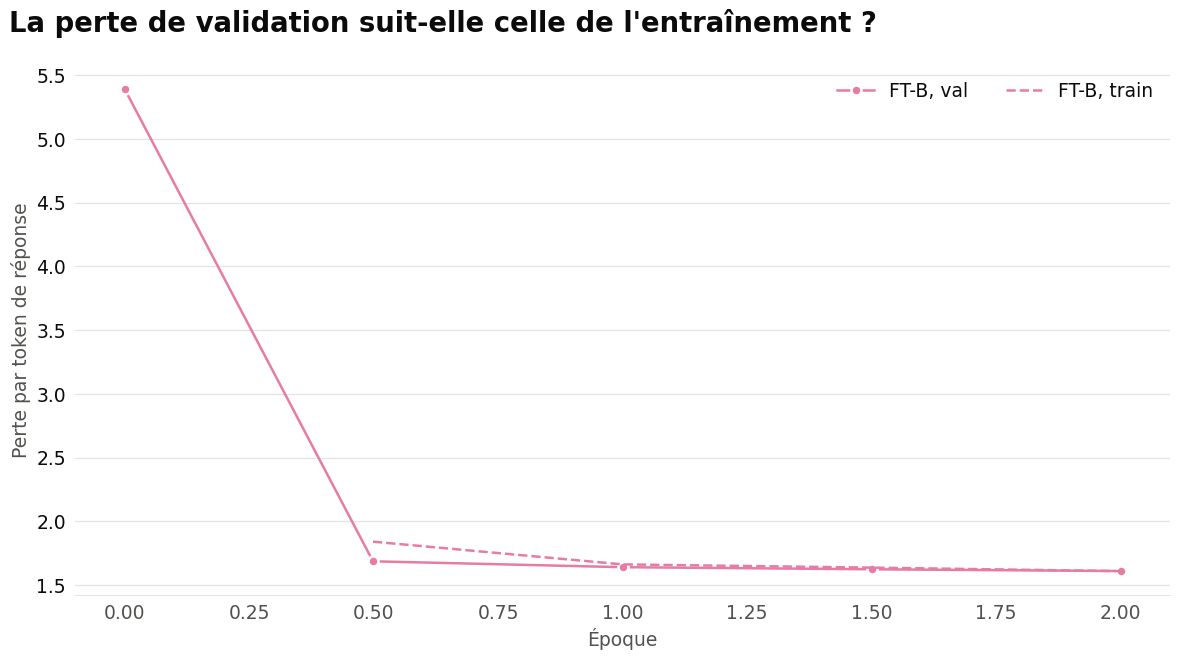

In [15]:
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3de"
METHOD_STYLES = {"Zero-shot": ("#2a78d6", "o"), "Few-shot": ("#eb6834", "s"), "RAG": ("#1f9e6e", "D"), "FT-A": ("#6250d6", "^"), "FT-B": ("#e87ba4", "v")}
plt.rcParams.update({
    "figure.figsize": (13.33, 7.5), "figure.dpi": 90, "savefig.dpi": 200, "figure.facecolor": "white",
    "font.size": 15, "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.axisbelow": True, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 1, "xtick.color": INK_2, "ytick.color": INK, "text.color": INK,
    "xtick.bottom": False, "ytick.left": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "legend.frameon": False,
})


def report_losses():
    fig, ax = plt.subplots()
    for version in REPORT_VERSIONS:
        label = VERSIONS[version]
        color = METHOD_STYLES[label][0]
        history = pd.read_csv(loss_path(version))
        display(history.set_index("step").round(4).rename_axis(label))
        ax.plot(history["epoch"], history["val_loss"], color=color, linewidth=2, marker="o", ms=8, markeredgecolor="white", markeredgewidth=2, label=f"{label}, val")
        ax.plot(history["epoch"], history["train_loss"], color=color, linewidth=2, linestyle="--", label=f"{label}, train")
    ax.set_xlabel("Époque")
    ax.set_ylabel("Perte par token de réponse")
    ax.grid(axis="x", visible=False)
    ax.legend(ncols=2, loc="upper right")
    fig.suptitle("La perte de validation suit-elle celle de l'entraînement ?", x=0.015, ha="left", fontsize=22, fontweight="bold")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "fig_perte.png")
    plt.show()


report_losses()

## 8. Comparaison aux autres méthodes

Les modèles de référence sont réentraînés avec les hyperparamètres de `02_baseline.ipynb` : MAE de 377 et de 369 attendues sur le test. Les autres lignes viennent des résultats de `03_prompting.ipynb` et `04_rag.ipynb`, dont la `Médiane des voisins`, la baseline sans LLM du RAG.

`Écart 100-400 / 1900+` compare la prédiction moyenne de ces deux tranches. Plus il est loin de l'écart réel, plus le modèle tire vers le milieu.

In [16]:
CATEGORICAL = ["country", "color", "opening_name", "eco", "result", "termination"]
NUMERIC = ["nb_moves", "nb_blunders", "nb_mistakes", "nb_inaccuracies", "acpl", "blunders_per_move"]
BEST_BOOSTING = {"learning_rate": 0.1, "max_depth": 3, "max_iter": 500, "loss": "absolute_error"}  # choisis sur val dans 02_baseline
MIN_CATEGORY_GAMES = 10


def fit_baseline(model):
    encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_CATEGORY_GAMES, sparse_output=False)
    columns = ColumnTransformer([("cat", encoder, CATEGORICAL), ("num", StandardScaler(), NUMERIC)])
    return make_pipeline(columns, model).fit(train[CATEGORICAL + NUMERIC], train["elo"])


def baseline_frame(model):
    prediction = np.clip(fit_baseline(model).predict(test[CATEGORICAL + NUMERIC]), ELO_MIN, ELO_MAX)
    return test[KEEP_COLUMNS].assign(prediction=prediction)


BASELINES = {
    "Constante": baseline_frame(DummyRegressor(strategy="median")),
    "Régression linéaire": baseline_frame(LinearRegression()),
    "Gradient boosting": baseline_frame(HistGradientBoostingRegressor(random_state=SEED, **BEST_BOOSTING)),
}


def elo_bin(values):
    return pd.cut(values, BINS, right=False, labels=BIN_LABELS).astype(str)


def scores(frame):
    """MAE, R², part dans la bonne tranche et erreur moyenne (prédit - vrai), sur les réponses lisibles."""
    readable = frame[frame["prediction"].notna()]
    result = {"Parties": len(frame), "Illisibles": len(frame) - len(readable), "MAE": np.nan, "R²": np.nan,
              "Bonne tranche (%)": np.nan, "Erreur moyenne": np.nan}
    if len(readable) >= 2:
        result.update({
            "MAE": mean_absolute_error(readable["elo"], readable["prediction"]),
            "R²": r2_score(readable["elo"], readable["prediction"]),
            "Bonne tranche (%)": 100 * np.mean(elo_bin(readable["prediction"]).to_numpy() == readable["elo_bin"].to_numpy()),
            "Erreur moyenne": (readable["prediction"] - readable["elo"]).mean(),
        })
    return result


def score_table(models, group_column=None, groups=None):
    """Scores par modèle : tout le jeu si group_column est None, sinon groupe par groupe."""
    rows = []
    for name, frame in models.items():
        if group_column is None:
            rows.append({"Modèle": name, "Groupe": "Global", **scores(frame)})
        else:
            rows += [{"Modèle": name, "Groupe": group, **scores(frame[frame[group_column] == group])} for group in groups]
    return pd.DataFrame(rows)


def display_pivots(table, groups, title):
    """Un tableau par métrique : groupes en lignes, modèles en colonnes."""
    order = list(MODELS)
    for metric, decimals in [("MAE", 0), ("Erreur moyenne", 0), ("R²", 3), ("Bonne tranche (%)", 1), ("Illisibles", 0)]:
        print(f"{title} - {metric}")
        display(table.pivot(index="Groupe", columns="Modèle", values=metric).reindex(index=groups, columns=order).round(decimals))


def spread(frame):
    """Écart de prédiction moyenne entre la tranche la plus haute et la plus basse."""
    means = frame.groupby("elo_bin")["prediction"].mean()
    return means["1900+"] - means["100-400"]


def report_scores():
    global MODELS, overall
    MODELS = {**BASELINES, "Médiane des voisins": previous["neighbor_median_test"]}
    for version in REPORT_VERSIONS:
        MODELS[f"LLM {VERSIONS[version]}"] = predictions[f"{version}_test"]
        MODELS[f"LLM {VERSIONS[version]} sans pays"] = predictions[f"{version}_no_country_test"]
    MODELS.update({"LLM RAG": previous["rag_test"], "LLM RAG sans pays": previous["rag_no_country_test"], "LLM few-shot": previous["few_shot_test"],
                   "LLM zero-shot": previous["zero_shot_test"], "LLM zero-shot sans pays": previous["no_country_test"]})
    overall = score_table(MODELS).drop(columns="Groupe").set_index("Modèle")
    overall["Corrélation"] = [frame["prediction"].corr(frame["elo"]) if frame["prediction"].nunique() > 1 else np.nan for frame in MODELS.values()]
    overall["Écart 100-400 / 1900+"] = [spread(frame) for frame in MODELS.values()]
    real_spread = test.groupby("elo_bin")["elo"].mean()
    print(f"Écart réel entre 100-400 et 1900+ : {real_spread['1900+'] - real_spread['100-400']:.0f} points")
    display(overall.round({"MAE": 0, "R²": 3, "Bonne tranche (%)": 1, "Erreur moyenne": 0, "Corrélation": 3, "Écart 100-400 / 1900+": 0}))
    save_atomically(overall.reset_index(), OUTPUT_DIR / "scores_global.csv")


report_scores()

Écart réel entre 100-400 et 1900+ : 1858 points


,Parties,Illisibles,MAE,R²,Bonne tranche (%),Erreur moyenne,Corrélation,Écart 100-400 / 1900+
Modèle,,,,,,,,
Constante,437,0,530.0,-0.002,15.3,-29.0,NaN,0.0
Régression linéaire,437,0,377.0,0.422,27.7,-10.0,0.651,789.0
Gradient boosting,437,0,369.0,0.440,26.1,-4.0,0.664,852.0
Médiane des voisins,437,0,453.0,0.177,20.8,27.0,0.477,561.0
LLM FT-B,437,0,382.0,0.383,28.6,103.0,0.680,1169.0
LLM FT-B sans pays,437,0,389.0,0.365,28.6,99.0,0.673,1156.0
LLM RAG,437,0,573.0,-0.315,16.2,275.0,0.306,402.0
LLM RAG sans pays,437,0,589.0,-0.379,14.9,320.0,0.292,364.0
LLM few-shot,437,0,507.0,0.062,15.6,-40.0,0.265,175.0


### Différences de MAE

Différence de MAE, partie par partie, tirage des parties avec remise. Un écart négatif signifie que le fine-tuning fait mieux que le modèle de comparaison. Si l'intervalle à 95 % exclut 0, la différence ne s'explique probablement pas par le choix des parties.

In [17]:
def bootstrap_mean(values, n_draws=10000, seed=SEED):
    """Intervalle à 95 % de la moyenne, en tirant les parties avec remise."""
    values = values[~np.isnan(values)]
    if len(values) == 0:
        return np.nan, np.nan
    draws = np.random.default_rng(seed).integers(0, len(values), (n_draws, len(values)))
    return tuple(np.percentile(values[draws].mean(axis=1), [2.5, 97.5]))


def absolute_error(frame):
    return (frame.set_index("game_id")["prediction"].reindex(test["game_id"]) - test.set_index("game_id")["elo"]).abs()


def mae_difference(first, second):
    difference = (absolute_error(MODELS[first]) - absolute_error(MODELS[second])).to_numpy()
    low, high = bootstrap_mean(difference)
    return {"Modèle": first, "Comparé à": second, "Différence de MAE": np.nanmean(difference), "IC 95 % bas": low, "IC 95 % haut": high,
            "IC exclut 0": bool(low > 0 or high < 0)}


REFERENCES = ["Médiane des voisins", "Gradient boosting", "Régression linéaire", "Constante", "LLM zero-shot", "LLM few-shot", "LLM RAG"]


def report_mae_differences():
    global mae_differences
    names = [f"LLM {VERSIONS[version]}{suffix}" for version in REPORT_VERSIONS for suffix in ["", " sans pays"]]
    rows = [mae_difference(name, other) for name in names for other in REFERENCES]
    if len(REPORT_VERSIONS) == 2:
        rows += [mae_difference("LLM FT-B", "LLM FT-A"), mae_difference("LLM FT-B sans pays", "LLM FT-A sans pays")]
    mae_differences = pd.DataFrame(rows)
    display(mae_differences.set_index(["Modèle", "Comparé à"]).round(1))
    save_atomically(mae_differences, OUTPUT_DIR / "comparaison_mae.csv")


report_mae_differences()

Différence de MAE  IC 95 % bas  \
Modèle             Comparé à                                             
LLM FT-B           Médiane des voisins              -70.3       -106.5   
                   Gradient boosting                 12.9        -17.3   
                   Régression linéaire                5.2        -24.5   
                   Constante                       -147.4       -187.8   
                   LLM zero-shot                   -261.5       -305.0   
                   LLM few-shot                    -125.1       -166.0   
                   LLM RAG                         -190.9       -233.6   
LLM FT-B sans pays Médiane des voisins              -64.1       -100.3   
                   Gradient boosting                 19.2        -11.3   
                   Régression linéaire               11.4        -18.7   
                   Constante                       -141.1       -182.0   
                   LLM zero-shot                   -255.3       -298.4   
                   LLM few-shot                    -118.8       -160.3   
                   LLM RAG                         -184.6       -227.0   

                                        IC 95 % haut  IC exclut 0  
Modèle             Comparé à                                       
LLM FT-B           Médiane des voisins         -33.7         True  
                   Gradient boosting            42.7        False  
                   Régression linéaire          34.5        False  
                   Constante                  -108.2         True  
                   LLM zero-shot              -219.4         True  
                   LLM few-shot                -84.3         True  
                   LLM RAG                    -149.1         True  
LLM FT-B sans pays Médiane des voisins         -27.8         True  
                   Gradient boosting            49.1        False  
                   Régression linéaire          41.6        False  
                   Constante                  -100.9         True  
                   LLM zero-shot              -213.5         True  
                   LLM few-shot                -77.7         True  
                   LLM RAG                    -142.0         True

### Valeurs les plus fréquentes

In [18]:
def report_frequent_values():
    def top_values(frame, n=10):
        shares = frame["prediction"].dropna().value_counts(normalize=True).head(n)
        return ", ".join(f"{value:.0f} ({100 * share:.1f} %)" for value, share in shares.items())


    frequent = pd.DataFrame([{"Modèle": name, "Valeurs distinctes": frame["prediction"].nunique(),
                              "Part de la plus fréquente (%)": 100 * frame["prediction"].value_counts(normalize=True).iloc[0],
                              "10 plus fréquentes": top_values(frame)}
                             for name, frame in MODELS.items() if name != "Constante"]).set_index("Modèle")
    with pd.option_context("display.max_colwidth", None):
        display(frequent.round(1))
    save_atomically(frequent.reset_index(), OUTPUT_DIR / "valeurs_frequentes.csv")


report_frequent_values()

,Valeurs distinctes,Part de la plus fréquente (%),10 plus fréquentes
Modèle,,,
Régression linéaire,433,1.1,"100 (1.1 %), 1437 (0.2 %), 2092 (0.2 %), 1752 (0.2 %), 1102 (0.2 %), 1194 (0.2 %), 1554 (0.2 %), 368 (0.2 %), 1006 (0.2 %), 1015 (0.2 %)"
Gradient boosting,437,0.2,"1412 (0.2 %), 438 (0.2 %), 996 (0.2 %), 1382 (0.2 %), 520 (0.2 %), 1763 (0.2 %), 376 (0.2 %), 942 (0.2 %), 1387 (0.2 %), 1161 (0.2 %)"
Médiane des voisins,390,0.7,"1600 (0.7 %), 1008 (0.7 %), 1584 (0.7 %), 1627 (0.7 %), 1390 (0.5 %), 1364 (0.5 %), 554 (0.5 %), 1464 (0.5 %), 1280 (0.5 %), 1936 (0.5 %)"
LLM FT-B,23,25.6,"1777 (25.6 %), 1017 (24.3 %), 1677 (14.6 %), 101 (9.6 %), 1377 (5.7 %), 1517 (3.9 %), 1577 (2.7 %), 300 (2.7 %), 371 (2.5 %), 2077 (1.6 %)"
LLM FT-B sans pays,23,25.4,"1777 (25.4 %), 1017 (23.6 %), 1677 (14.4 %), 101 (10.1 %), 1377 (6.2 %), 1517 (3.9 %), 1577 (3.2 %), 300 (2.7 %), 371 (2.5 %), 2077 (1.6 %)"
LLM RAG,199,6.2,"1850 (6.2 %), 1450 (5.9 %), 1650 (5.3 %), 1350 (5.3 %), 1580 (3.9 %), 1750 (3.0 %), 2050 (2.7 %), 1420 (2.5 %), 1320 (2.3 %), 1200 (2.1 %)"
LLM RAG sans pays,207,6.2,"1450 (6.2 %), 1850 (5.9 %), 1650 (3.9 %), 1350 (3.9 %), 1580 (3.2 %), 1500 (3.0 %), 1700 (2.7 %), 1200 (2.7 %), 1100 (2.5 %), 1420 (2.3 %)"
LLM few-shot,25,46.9,"1024 (46.9 %), 1287 (31.6 %), 1087 (5.0 %), 1027 (3.0 %), 1278 (2.1 %), 412 (1.8 %), 1124 (1.6 %), 1892 (0.9 %), 1387 (0.9 %), 1682 (0.9 %)"
LLM zero-shot,8,44.9,"1800 (44.9 %), 1400 (25.9 %), 1500 (13.3 %), 1600 (6.9 %), 1850 (5.0 %), 1300 (3.0 %), 1650 (0.9 %), 1450 (0.2 %)"


### Par pays

In [19]:
def report_by_country():
    by_country = score_table(MODELS, "country", COUNTRY_ORDER)
    display_pivots(by_country, COUNTRY_ORDER, "Par pays")
    save_atomically(by_country, OUTPUT_DIR / "scores_par_pays.csv")


report_by_country()

Par pays - MAE


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
BR,557.0,434.0,429.0,487.0,385.0,393.0,631.0,675.0,530.0,673.0,670.0
DE,450.0,335.0,333.0,429.0,344.0,347.0,508.0,504.0,438.0,582.0,526.0
FR,542.0,386.0,384.0,449.0,413.0,418.0,606.0,618.0,517.0,662.0,639.0
IN,551.0,347.0,328.0,467.0,319.0,332.0,535.0,561.0,515.0,654.0,631.0
US,526.0,368.0,346.0,433.0,407.0,410.0,528.0,529.0,520.0,615.0,621.0


Par pays - Erreur moyenne


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
BR,-60.0,20.0,-2.0,70.0,107.0,96.0,339.0,412.0,-105.0,448.0,406.0
DE,-97.0,-58.0,-97.0,-6.0,56.0,48.0,206.0,219.0,-51.0,452.0,347.0
FR,-25.0,-13.0,17.0,33.0,123.0,123.0,317.0,363.0,-42.0,460.0,408.0
IN,-9.0,-36.0,-18.0,22.0,64.0,73.0,264.0,297.0,-22.0,530.0,413.0
US,43.0,48.0,54.0,2.0,135.0,122.0,171.0,227.0,28.0,403.0,428.0


Par pays - R²


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
BR,-0.008,0.384,0.426,0.274,0.453,0.443,-0.277,-0.456,0.108,-0.373,-0.354
DE,-0.034,0.386,0.394,-0.079,0.277,0.267,-0.564,-0.541,0.008,-0.809,-0.451
FR,-0.001,0.440,0.438,0.223,0.359,0.339,-0.361,-0.415,0.076,-0.564,-0.456
IN,-0.000,0.491,0.505,0.117,0.592,0.561,-0.223,-0.294,0.066,-0.701,-0.470
US,-0.006,0.339,0.405,0.137,0.127,0.119,-0.164,-0.142,-0.050,-0.577,-0.643


Par pays - Bonne tranche (%)


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
BR,18.6,27.1,18.6,18.6,35.7,37.1,18.6,17.1,17.1,12.9,12.9
DE,16.9,30.8,32.3,24.6,27.7,27.7,16.9,15.4,15.4,13.8,13.8
FR,16.4,27.5,25.7,19.9,25.1,25.1,14.0,13.5,17.5,14.0,13.5
IN,14.3,31.4,31.4,17.1,31.4,30.0,18.6,14.3,14.3,12.9,8.6
US,8.2,21.3,23.0,26.2,27.9,27.9,16.4,16.4,9.8,16.4,18.0


Par pays - Illisibles


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
BR,0,0,0,0,0,0,0,0,0,0,0
DE,0,0,0,0,0,0,0,0,0,0,0
FR,0,0,0,0,0,0,0,0,0,0,0
IN,0,0,0,0,0,0,0,0,0,0,0
US,0,0,0,0,0,0,0,0,0,0,0


### Par tranche d'Elo

Le R² d'une tranche se lit avec prudence : l'Elo varie peu à l'intérieur d'une tranche, si bien qu'il est souvent très négatif même pour un bon modèle. La MAE, l'erreur moyenne et la part de bonnes tranches sont plus parlantes ici.

In [20]:
def report_by_bin():
    by_bin = score_table(MODELS, "elo_bin", BIN_LABELS)
    display_pivots(by_bin, BIN_LABELS, "Par tranche")
    save_atomically(by_bin, OUTPUT_DIR / "scores_par_tranche.csv")


report_by_bin()

Par tranche - MAE


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
100-400,878.0,470.0,418.0,621.0,383.0,398.0,952.0,1005.0,785.0,1309.0,1248.0
400-700,603.0,438.0,393.0,455.0,559.0,567.0,814.0,852.0,591.0,1091.0,1037.0
700-1000,285.0,304.0,313.0,411.0,563.0,577.0,623.0,701.0,254.0,784.0,707.0
1000-1300,75.0,247.0,301.0,340.0,331.0,344.0,441.0,441.0,143.0,489.0,430.0
1300-1600,322.0,171.0,199.0,253.0,290.0,287.0,280.0,282.0,327.0,235.0,237.0
1600-1900,615.0,375.0,354.0,422.0,174.0,173.0,355.0,311.0,592.0,177.0,231.0
1900+,980.0,645.0,614.0,684.0,389.0,387.0,577.0,565.0,898.0,478.0,528.0


Par tranche - Erreur moyenne


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
100-400,878.0,430.0,406.0,613.0,299.0,315.0,942.0,996.0,785.0,1309.0,1248.0
400-700,603.0,400.0,362.0,414.0,331.0,310.0,745.0,806.0,582.0,1091.0,1037.0
700-1000,285.0,241.0,220.0,285.0,313.0,299.0,549.0,624.0,225.0,784.0,707.0
1000-1300,-8.0,-33.0,-17.0,33.0,152.0,140.0,288.0,305.0,-48.0,489.0,430.0
1300-1600,-322.0,-95.0,-104.0,-75.0,105.0,108.0,115.0,154.0,-294.0,189.0,140.0
1600-1900,-615.0,-348.0,-277.0,-364.0,-87.0,-84.0,-166.0,-114.0,-592.0,-123.0,-178.0
1900+,-980.0,-638.0,-600.0,-684.0,-389.0,-387.0,-513.0,-497.0,-898.0,-478.0,-528.0


Par tranche - R²


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
100-400,-112.217,-45.056,-35.710,-78.367,-35.229,-37.195,-162.488,-174.368,-96.572,-254.328,-232.241
400-700,-56.432,-41.108,-37.770,-51.724,-60.397,-62.236,-139.797,-145.937,-60.229,-190.367,-172.599
700-1000,-11.837,-18.980,-22.061,-32.414,-59.884,-61.568,-73.670,-93.091,-12.229,-93.513,-78.413
1000-1300,-0.010,-10.993,-16.882,-20.395,-22.486,-24.659,-34.892,-34.601,-4.013,-36.438,-30.580
1300-1600,-13.489,-5.990,-7.209,-12.229,-17.299,-17.373,-16.865,-17.243,-16.030,-9.305,-8.673
1600-1900,-56.270,-27.957,-26.463,-40.122,-9.481,-9.347,-31.607,-23.317,-55.059,-6.943,-10.830
1900+,-10.220,-4.662,-4.301,-5.624,-1.659,-1.604,-4.046,-3.892,-8.616,-2.522,-3.253


Par tranche - Bonne tranche (%)


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
100-400,0.0,24.1,17.2,10.3,58.6,56.9,12.1,8.6,0.0,0.0,0.0
400-700,0.0,14.1,29.7,28.1,0.0,0.0,9.4,4.7,4.7,0.0,0.0
700-1000,0.0,22.6,29.0,21.0,0.0,0.0,3.2,3.2,0.0,0.0,0.0
1000-1300,100.0,40.3,29.9,20.9,41.8,38.8,11.9,11.9,95.5,0.0,0.0
1300-1600,0.0,65.5,43.1,32.8,17.2,19.0,36.2,32.8,0.0,36.2,41.4
1600-1900,0.0,22.1,23.5,23.5,72.1,73.5,27.9,29.4,1.5,58.8,50.0
1900+,0.0,6.7,10.0,8.3,6.7,8.3,13.3,13.3,0.0,0.0,0.0


Par tranche - Illisibles


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
100-400,0,0,0,0,0,0,0,0,0,0,0
400-700,0,0,0,0,0,0,0,0,0,0,0
700-1000,0,0,0,0,0,0,0,0,0,0,0
1000-1300,0,0,0,0,0,0,0,0,0,0,0
1300-1600,0,0,0,0,0,0,0,0,0,0,0
1600-1900,0,0,0,0,0,0,0,0,0,0,0
1900+,0,0,0,0,0,0,0,0,0,0,0


### Sans les parties de leaderboard

Comme dans `02_baseline.ipynb` : ces parties pèsent plus lourd dans la tranche 1900+ de certains pays, ce qui peut déformer la comparaison.

In [21]:
def report_without_leaderboard():
    without_leaderboard = {name: frame[frame["source"] != "leaderboard"] for name, frame in MODELS.items()}
    by_country_no_lb = pd.concat([score_table(without_leaderboard), score_table(without_leaderboard, "country", COUNTRY_ORDER)])
    display_pivots(by_country_no_lb, ["Global"] + COUNTRY_ORDER, "Sans leaderboard")
    save_atomically(by_country_no_lb, OUTPUT_DIR / "scores_sans_leaderboard.csv")


report_without_leaderboard()

Sans leaderboard - MAE


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
Global,503.0,359.0,355.0,440.0,371.0,378.0,565.0,581.0,486.0,635.0,612.0
BR,476.0,380.0,387.0,443.0,343.0,355.0,611.0,659.0,466.0,653.0,644.0
DE,450.0,335.0,333.0,429.0,344.0,347.0,508.0,504.0,438.0,582.0,526.0
FR,507.0,361.0,367.0,434.0,401.0,406.0,595.0,607.0,488.0,647.0,621.0
IN,551.0,347.0,328.0,467.0,319.0,332.0,535.0,561.0,515.0,654.0,631.0
US,526.0,368.0,346.0,433.0,407.0,410.0,528.0,529.0,520.0,615.0,621.0


Sans leaderboard - Erreur moyenne


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
Global,9.0,17.0,19.0,51.0,126.0,122.0,304.0,349.0,-8.0,495.0,438.0
BR,59.0,109.0,73.0,157.0,187.0,172.0,433.0,512.0,-9.0,554.0,515.0
DE,-97.0,-58.0,-97.0,-6.0,56.0,48.0,206.0,219.0,-51.0,452.0,347.0
FR,26.0,22.0,46.0,62.0,151.0,151.0,356.0,404.0,1.0,508.0,458.0
IN,-9.0,-36.0,-18.0,22.0,64.0,73.0,264.0,297.0,-22.0,530.0,413.0
US,43.0,48.0,54.0,2.0,135.0,122.0,171.0,227.0,28.0,403.0,428.0


Sans leaderboard - R²


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
Global,-0.000,0.410,0.406,0.100,0.325,0.302,-0.491,-0.567,0.028,-0.788,-0.635
BR,-0.011,0.309,0.315,0.094,0.323,0.288,-0.881,-1.174,0.008,-1.037,-0.965
DE,-0.034,0.386,0.394,-0.079,0.277,0.267,-0.564,-0.541,0.008,-0.809,-0.451
FR,-0.002,0.429,0.382,0.121,0.266,0.241,-0.603,-0.671,0.034,-0.841,-0.683
IN,-0.000,0.491,0.505,0.117,0.592,0.561,-0.223,-0.294,0.066,-0.701,-0.470
US,-0.006,0.339,0.405,0.137,0.127,0.119,-0.164,-0.142,-0.050,-0.577,-0.643


Sans leaderboard - Bonne tranche (%)


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
Global,15.7,28.1,26.0,20.8,28.6,28.3,15.7,14.3,15.9,14.3,13.6
BR,20.0,29.2,16.9,18.5,36.9,36.9,16.9,15.4,18.5,13.8,13.8
DE,16.9,30.8,32.3,24.6,27.7,27.7,16.9,15.4,15.4,13.8,13.8
FR,16.9,27.7,25.9,19.9,24.7,24.7,13.3,12.7,18.1,14.5,13.9
IN,14.3,31.4,31.4,17.1,31.4,30.0,18.6,14.3,14.3,12.9,8.6
US,8.2,21.3,23.0,26.2,27.9,27.9,16.4,16.4,9.8,16.4,18.0


Sans leaderboard - Illisibles


Modèle,Constante,Régression linéaire,Gradient boosting,Médiane des voisins,LLM FT-B,LLM FT-B sans pays,LLM RAG,LLM RAG sans pays,LLM few-shot,LLM zero-shot,LLM zero-shot sans pays
Groupe,,,,,,,,,,,
Global,0,0,0,0,0,0,0,0,0,0,0
BR,0,0,0,0,0,0,0,0,0,0,0
DE,0,0,0,0,0,0,0,0,0,0,0
FR,0,0,0,0,0,0,0,0,0,0,0
IN,0,0,0,0,0,0,0,0,0,0,0
US,0,0,0,0,0,0,0,0,0,0,0


## 9. Test de biais

Chaque partie de `bias_test.jsonl` est présentée 5 fois, seul le pays change, un prompt à la fois. On compare chaque pays à la France, puis au prompt sans pays, qui ne suppose pas que la France soit neutre. Le zero-shot, le few-shot et le RAG viennent des notebooks 03 et 04, eux aussi sans lot.

**Lecture.** Un écart de +50 signifie qu'à partie identique, le modèle donne en moyenne 50 points de plus qu'avec cette référence. Si l'intervalle à 95 % exclut 0, l'écart ne s'explique probablement pas par le choix des parties.

**Limites.**
- Le bootstrap porte sur les parties, mais les 140 parties viennent de 79 joueurs : les intervalles sont un peu trop étroits.
- Les 5 approches donnent 45 intervalles : un intervalle excluant 0 de justesse peut être dû au hasard.
- Un écart vient du seul pays, mais il ne dit pas si c'est un stéréotype sur le pays ou un effet du mot lui-même.

In [22]:
def bias_deltas(frame):
    """Une ligne par partie, une colonne par pays : Elo prédit pour ce pays moins Elo prédit pour la France."""
    wide = frame.pivot(index="game_id", columns="country", values="prediction")
    return wide[BIAS_COUNTRIES].sub(wide["FR"], axis=0)


def versus_neutral(frame, neutral_frame):
    """Une ligne par partie, une colonne par pays : Elo prédit pour ce pays moins Elo prédit sans pays."""
    neutral = neutral_frame.set_index("game_id")["prediction"]
    wide = frame.pivot(index="game_id", columns="country", values="prediction")
    return wide[COUNTRY_ORDER].sub(neutral.reindex(wide.index), axis=0)


def delta_summary(deltas, variant):
    rows = []
    for country in deltas.columns:
        values = deltas[country].to_numpy()
        low, high = bootstrap_mean(values)
        rows.append({
            "Variante": variant, "Pays": COUNTRY_NAMES[country], "country": country, "Parties comparées": int((~np.isnan(values)).sum()),
            "Écart moyen": np.nanmean(values) if (~np.isnan(values)).any() else np.nan, "IC 95 % bas": low, "IC 95 % haut": high,
            "Prédiction modifiée (%)": 100 * np.nanmean(values[~np.isnan(values)] != 0) if (~np.isnan(values)).any() else np.nan,
            "IC exclut 0": bool(low > 0 or high < 0),
        })
    return rows


def report_bias():
    global BIAS_METHODS, bias_france, bias_neutral
    # méthode -> (prédictions avec pays, prédictions sans pays)
    BIAS_METHODS = {
        "Zero-shot": (previous["zero_shot_bias"], previous["no_country_bias"]),
        "Few-shot": (previous["few_shot_bias"], previous["few_shot_no_country_bias"]),
        "RAG": (previous["rag_bias"], previous["rag_no_country_bias"]),
    }
    for version in REPORT_VERSIONS:
        BIAS_METHODS[VERSIONS[version]] = (predictions[f"{version}_bias"], predictions[f"{version}_no_country_bias"])
    bias_france = pd.DataFrame([row for label, (frame, _) in BIAS_METHODS.items() for row in delta_summary(bias_deltas(frame), label)])
    bias_neutral = pd.DataFrame([row for label, (frame, neutral) in BIAS_METHODS.items()
                                 for row in delta_summary(versus_neutral(frame, neutral), label)])
    print("Écart à la France")
    display(bias_france.drop(columns="country").set_index(["Variante", "Pays"]).round(1))
    print("Écart au prompt sans pays")
    display(bias_neutral.drop(columns="country").set_index(["Variante", "Pays"]).round(1))
    save_atomically(bias_france, OUTPUT_DIR / "biais_ecarts_france.csv")
    save_atomically(bias_neutral, OUTPUT_DIR / "biais_ecarts_sans_pays.csv")
    save_atomically(pd.concat({VERSIONS[version]: bias_deltas(predictions[f"{version}_bias"]) for version in REPORT_VERSIONS}, names=["Variante"]).reset_index(),
                    OUTPUT_DIR / "biais_ecarts_par_partie.csv")


report_bias()

Écart à la France


Parties comparées  Écart moyen  IC 95 % bas  \
Variante  Pays                                                      
Zero-shot Inde                      140         49.3         37.1   
          États-Unis                140        -91.1       -108.2   
          Brésil                    140        -11.4        -20.7   
          Allemagne                 140         49.3         38.6   
Few-shot  Inde                      140          7.1         -3.9   
          États-Unis                140         37.1         17.4   
          Brésil                    140        -61.9        -90.7   
          Allemagne                 140         46.1         27.1   
RAG       Inde                      140         17.5         -1.1   
          États-Unis                140         12.0         -3.3   
          Brésil                    140         -8.5        -14.8   
          Allemagne                 140         15.6          0.5   
FT-B      Inde                      140          0.3        -11.4   
          États-Unis                140          3.9         -1.4   
          Brésil                    140         -4.5        -16.3   
          Allemagne                 140         -3.8        -15.6   

                      IC 95 % haut  Prédiction modifiée (%)  IC exclut 0  
Variante  Pays                                                            
Zero-shot Inde                62.1                     37.1         True  
          États-Unis         -75.0                     52.9         True  
          Brésil              -3.2                     28.6         True  
          Allemagne           60.7                     42.1         True  
Few-shot  Inde                20.1                     15.7        False  
          États-Unis          58.4                     22.9         True  
          Brésil             -36.8                     25.0         True  
          Allemagne           69.4                     20.0         True  
RAG       Inde                40.6                     23.6        False  
          États-Unis          34.7                     16.4        False  
          Brésil              -2.9                     18.6         True  
          Allemagne           34.7                     15.0         True  
FT-B      Inde                 9.7                      5.0        False  
          États-Unis          11.0                      6.4        False  
          Brésil               5.0                      5.0        False  
          Allemagne            5.9                      6.4        False

Écart au prompt sans pays


Parties comparées  Écart moyen  IC 95 % bas  \
Variante  Pays                                                      
Zero-shot Brésil                    140         40.0         29.3   
          Allemagne                 140        100.7         81.8   
          France                    140         51.4         38.2   
          Inde                      140        100.7         81.1   
          États-Unis                140        -39.6        -53.9   
Few-shot  Brésil                    140        -79.3       -111.0   
          Allemagne                 140         28.7          3.2   
          France                    140        -17.4        -42.8   
          Inde                      140        -10.3        -36.0   
          États-Unis                140         19.7         -1.4   
RAG       Brésil                    140        -52.2        -81.4   
          Allemagne                 140        -28.1        -52.7   
          France                    140        -43.7        -72.7   
          Inde                      140        -26.1        -53.7   
          États-Unis                140        -31.7        -52.3   
FT-B      Brésil                    140         -2.3         -7.6   
          Allemagne                 140         -1.6         -7.2   
          France                    140          2.2         -7.0   
          Inde                      140          2.5         -1.6   
          États-Unis                140          6.1         -1.7   

                      IC 95 % haut  Prédiction modifiée (%)  IC exclut 0  
Variante  Pays                                                            
Zero-shot Brésil              51.8                     39.3         True  
          Allemagne          120.4                     60.0         True  
          France              65.7                     34.3         True  
          Inde               120.7                     55.7         True  
          États-Unis         -26.4                     27.1         True  
Few-shot  Brésil             -51.5                     34.3         True  
          Allemagne           55.5                     20.7         True  
          France               7.3                     24.3        False  
          Inde                15.8                     28.6        False  
          États-Unis          41.7                     18.6        False  
RAG       Brésil             -29.0                     37.9         True  
          Allemagne          -10.7                     25.7         True  
          France             -21.2                     27.9         True  
          Inde                -3.5                     32.1         True  
          États-Unis         -14.5                     28.6         True  
FT-B      Brésil               1.6                      4.3        False  
          Allemagne            3.0                      5.0        False  
          France              13.6                      5.7        False  
          Inde                 7.1                      5.7        False  
          États-Unis          17.1                      8.6        False

### Le pays tiré au hasard réduit-il le biais ?

`Étendue par partie` : pour une partie, la plus haute prédiction des 5 pays moins la plus basse. Elle vaut 0 si le pays ne change rien, et elle ne dépend d'aucun pays de référence. Le second tableau donne, partie par partie, FT-B moins FT-A : une étendue négative signifie que FT-B dépend moins du pays. Pour les écarts à la France, une différence positive signifie seulement que FT-B donne à ce pays plus de points que FT-A : c'est à rapprocher du signe de l'écart de FT-A.

Ce test direct demande les deux versions. Avec une seule version par exécution, il n'apparaît qu'à la section 12 de `05_finetuning.ipynb`.

In [23]:
def game_range(frame):
    wide = frame.pivot(index="game_id", columns="country", values="prediction")
    return wide.max(axis=1, skipna=False) - wide.min(axis=1, skipna=False)


def report_debiasing():
    global game_ranges, debiasing
    rows = []
    for label, (frame, _) in BIAS_METHODS.items():
        values = game_range(frame)
        low, high = bootstrap_mean(values.to_numpy())
        rows.append({"Méthode": label, "Étendue moyenne": values.mean(), "IC 95 % bas": low, "IC 95 % haut": high, "Parties où le pays change la prédiction (%)": 100 * (values.dropna() > 0).mean()})
    game_ranges = pd.DataFrame(rows).set_index("Méthode")
    display(game_ranges.round(1))
    save_atomically(game_ranges.reset_index(), OUTPUT_DIR / "biais_etendue_par_partie.csv")

    if len(REPORT_VERSIONS) < 2:
        print("Test direct FT-B contre FT-A : il faut les deux versions (section 12).")
        return
    range_change = (game_range(predictions["ft_b_bias"]) - game_range(predictions["ft_a_bias"])).to_numpy()
    low, high = bootstrap_mean(range_change)
    print(f"Étendue, FT-B moins FT-A : {np.nanmean(range_change):+.1f} points, IC 95 % [{low:.1f} ; {high:.1f}]")
    gap_change = bias_deltas(predictions["ft_b_bias"]) - bias_deltas(predictions["ft_a_bias"])
    debiasing = pd.DataFrame(delta_summary(gap_change, "FT-B moins FT-A"))
    display(debiasing.drop(columns=["country", "Prédiction modifiée (%)"]).set_index("Pays").round(1))
    save_atomically(debiasing, OUTPUT_DIR / "biais_ft_b_moins_ft_a.csv")


report_debiasing()

,Étendue moyenne,IC 95 % bas,IC 95 % haut,Parties où le pays change la prédiction (%)
Méthode,,,,
Zero-shot,150.0,130.7,169.3,77.9
Few-shot,120.0,88.0,154.9,42.1
RAG,57.7,33.0,87.2,36.4
FT-B,15.8,6.1,28.6,10.0


Test direct FT-B contre FT-A : il faut les deux versions (section 12).


### Comparaison des approches

Le graphique final compare le biais de toutes les méthodes disponibles : chaque point est un écart moyen, chaque barre son intervalle à 95 %. Avec les deux versions, il réunit les 5 approches.

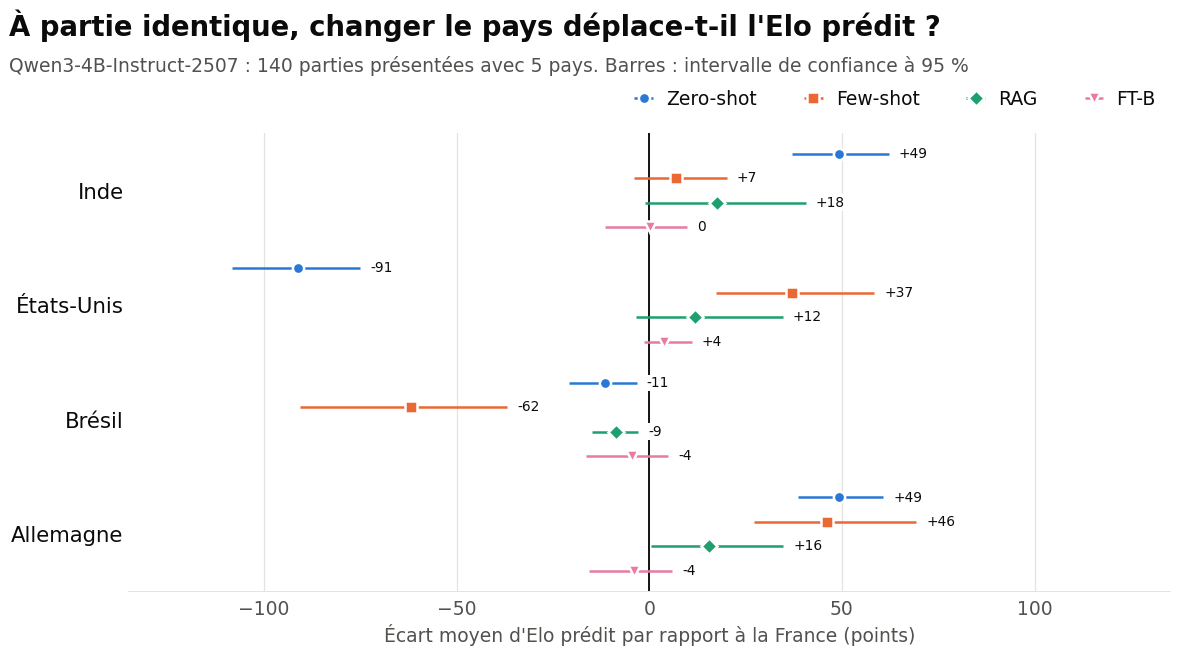

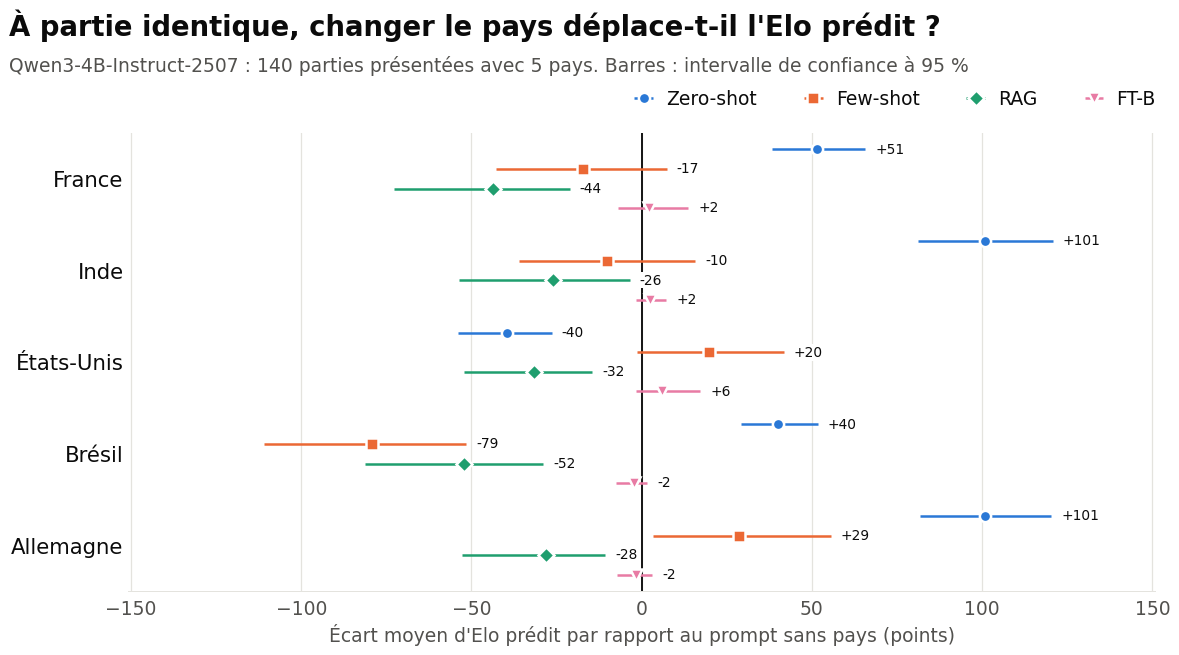

In [24]:
def plot_bias(table, countries, reference, path):
    fig, ax = plt.subplots()
    methods = [method for method in METHOD_STYLES if method in set(table["Variante"])]
    offsets = dict(zip(methods, np.linspace(-0.32, 0.32, len(methods))))
    positions = {COUNTRY_NAMES[country]: rank for rank, country in enumerate(countries)}
    for variant in methods:
        color, marker = METHOD_STYLES[variant]
        rows = table[table["Variante"] == variant]
        y = rows["Pays"].map(positions) + offsets[variant]
        errors = [rows["Écart moyen"] - rows["IC 95 % bas"], rows["IC 95 % haut"] - rows["Écart moyen"]]
        ax.errorbar(rows["Écart moyen"], y, xerr=errors, fmt=marker, color=color, ms=9, elinewidth=2, capsize=0,
                    markeredgecolor="white", markeredgewidth=2, label=variant, zorder=3)
        for value, high, position in zip(rows["Écart moyen"], rows["IC 95 % haut"], y):
            if not np.isnan(value):
                label = f"{round(value):+d}" if round(value) else "0"
                ax.annotate(label, (high, position), xytext=(8, 0), textcoords="offset points", ha="left", va="center",
                            fontsize=11, color=INK, zorder=4, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})

    largest = np.nanmax(np.abs(table[["IC 95 % bas", "IC 95 % haut"]].to_numpy()))
    half_range = max(20, 1.25 * (0 if np.isnan(largest) else largest))
    ax.set_xlim(-half_range, half_range)
    ax.axvline(0, color=INK, linewidth=1.5, zorder=2)
    ax.set_yticks(list(positions.values()), list(positions.keys()))
    ax.set_ylim(len(positions) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0, labelsize=17)
    ax.set_xlabel(f"Écart moyen d'Elo prédit par rapport {reference} (points)")
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="center right", bbox_to_anchor=(0.985, 0.84), ncols=len(methods), handletextpad=0.2)

    fig.text(0.015, 0.95, "À partie identique, changer le pays déplace-t-il l'Elo prédit ?", fontsize=22, fontweight="bold", va="center")
    fig.text(0.015, 0.89, f"{MODEL_NAME.split('/')[-1]} : {bias_test['game_id'].nunique()} parties présentées avec 5 pays. "
                          "Barres : intervalle de confiance à 95 %", fontsize=15, color=INK_2, va="center")
    fig.tight_layout(rect=(0, 0, 1, 0.82))
    fig.savefig(path)
    plt.show()


def report_bias_figures():
    plot_bias(bias_france, BIAS_COUNTRIES, "à la France", OUTPUT_DIR / "fig_biais_pays.png")
    plot_bias(bias_neutral, ["FR", "IN", "US", "BR", "DE"], "au prompt sans pays", OUTPUT_DIR / "fig_biais_sans_pays.png")


report_bias_figures()

## 10. Le pays change-t-il l'erreur ?

Sur le test, on compare l'erreur absolue de chaque version avec et sans le pays, partie par partie. Un écart négatif signifie que le pays réduit l'erreur.

Le jeu est équilibré par quotas : le pays ne porte aucune information utile sur l'Elo (voir `01_eda.ipynb`). Si le mentionner change les scores, c'est donc un effet du modèle et non un signal des données.

In [25]:
def report_country_effect():
    global country_effect_test
    rows = []
    for version in REPORT_VERSIONS:
        named = predictions[f"{version}_test"].set_index("game_id")
        without = predictions[f"{version}_no_country_test"].set_index("game_id").reindex(named.index)
        error_change = (named["prediction"] - named["elo"]).abs() - (without["prediction"] - named["elo"]).abs()
        for group in ["Global"] + COUNTRY_ORDER:
            values = error_change if group == "Global" else error_change[named["country"] == group]
            low, high = bootstrap_mean(values.to_numpy())
            rows.append({"Version": VERSIONS[version], "Groupe": group, "Parties comparées": int(values.notna().sum()), "Variation de l'erreur absolue": values.mean(),
                         "IC 95 % bas": low, "IC 95 % haut": high, "Prédiction modifiée (%)": 100 * (values.dropna() != 0).mean()})
    country_effect_test = pd.DataFrame(rows).set_index(["Version", "Groupe"])
    display(country_effect_test.round(1))
    save_atomically(country_effect_test.reset_index(), OUTPUT_DIR / "pays_effet_sur_erreur.csv")


report_country_effect()

Parties comparées  Variation de l'erreur absolue  IC 95 % bas  \
Version Groupe                                                                  
FT-B    Global                437                           -6.3        -14.5   
        BR                     70                           -8.0        -35.1   
        DE                     65                           -2.9        -11.8   
        FR                    171                           -5.0        -19.1   
        IN                     70                          -13.0        -40.9   
        US                     61                           -3.7         -8.8   

                IC 95 % haut  Prédiction modifiée (%)  
Version Groupe                                         
FT-B    Global           0.4                      7.1  
        BR               8.6                      4.3  
        DE               6.1                     10.8  
        FR               5.9                      6.4  
        IN               3.2                      8.6  
        US               0.2                      6.6

## 11. Récupérer les résultats

Tous les CSV et les graphiques de cette exécution sont réunis dans `/kaggle/working/resultats_finetuning.zip`. Avec `resultats_finetuning/` et `adaptateurs/`, il forme la sortie de la version : onglet *Output* de la page du notebook, une fois la version terminée. Les adaptateurs ne sont pas dans le zip.

In [26]:
def archive_results(name):
    archive = shutil.make_archive(str(ROOT_DIR / name), "zip", OUTPUT_DIR)
    print(f"{archive} : {len(list(OUTPUT_DIR.iterdir()))} fichiers")


archive_results("resultats_finetuning")

/kaggle/working/resultats_finetuning.zip : 22 fichiers


## 12. Rassembler FT-A et FT-B

Le rassemblement se fait dans `05_finetuning.ipynb`, sur Colab et sans GPU (voir la marche à suivre en haut). Il demande, en plus de la sortie complète d'une version, les 6 fichiers de l'autre, tirés de `resultats_finetuning/` (ici pour FT-B ; remplacer `ft_b` par `ft_a` dans l'autre sens) :

- `predictions_ft_b_test.csv`, `predictions_ft_b_no_country_test.csv`, `predictions_ft_b_bias.csv`, `predictions_ft_b_no_country_bias.csv` ;
- `perte_ft_b.csv` ;
- `config_ft_b.json`.

**Vérifications de `05_finetuning.ipynb`.** Mêmes parties, mêmes Elo, et mêmes réglages d'entraînement : deux versions entraînées avec des `EPOCHS` différents ne sont pas comparables, et la section s'arrête. Si les moteurs ou les versions de bibliothèques diffèrent, elle l'affiche seulement : c'est une réserve à signaler, pas une erreur.

La cellule ci-dessous est celle de `05_finetuning.ipynb`. Avec `VARIANTS = ["A", "B"]`, les tableaux ci-dessus sont déjà complets ; avec une seule version, elle liste les fichiers à reprendre de l'autre exécution.

In [27]:
REPORT_STEPS = [report_responses, report_losses, report_scores, report_mae_differences, report_frequent_values, report_by_country, report_by_bin,
                report_without_leaderboard, report_bias, report_debiasing, report_bias_figures, report_country_effect]


def required_files(version):
    return [prediction_path(name) for name in version_variants(version)] + [loss_path(version), config_path(version)]


def check_other_version(other, own):
    """Refuse des fichiers incomplets ou des réglages différents ; signale un moteur différent."""
    for name in version_variants(other):
        frame = load_saved(name)
        expected = VARIANT_PLAN[name][1]
        if len(frame) != len(expected) or set(zip(frame["game_id"], frame["country"])) != set(zip(expected["game_id"], expected["country"])):
            raise ValueError(f"{prediction_path(name).name} : pas les parties attendues. Déposer le fichier complet de l'autre compte.")
        if frame.set_index(["game_id", "country"])["elo"].reindex(pd.MultiIndex.from_frame(expected[["game_id", "country"]])).tolist() != expected["elo"].tolist():
            raise ValueError(f"{prediction_path(name).name} : les Elo ne correspondent pas")
    own_config, other_config = (json.loads(config_path(version).read_text(encoding="utf-8")) for version in [own, other])
    different = {key: (own_config["settings"].get(key), other_config["settings"].get(key)) for key in own_config["settings"].keys() | other_config["settings"].keys()
                 if own_config["settings"].get(key) != other_config["settings"].get(key)}
    if different:
        raise ValueError(f"Réglages différents entre {VERSIONS[own]} et {VERSIONS[other]} : {different}. Les deux versions ne sont pas comparables.")
    for key in ["engine", "transformers", "peft"]:
        if own_config[key] != other_config[key]:
            print(f"Réserve à signaler : {key} différent ({VERSIONS[own]} : {own_config[key]}, {VERSIONS[other]} : {other_config[key]})")


def gather_results():
    if len(ACTIVE_VERSIONS) == 2:
        print("Les deux versions viennent de cette exécution : les tableaux ci-dessus sont déjà complets.")
        return
    own = ACTIVE_VERSIONS[0]
    other = next(version for version in VERSIONS if version != own)
    missing = [path.name for path in required_files(other) if not path.exists()]
    if missing:
        print(f"{VERSIONS[other]} absente : tableaux limités à {VERSIONS[own]}. Pour rassembler les deux versions, "
              f"voir la section 12 de 05_finetuning.ipynb. Fichiers de {VERSIONS[other]} qu'elle demande : {missing}")
        return
    check_other_version(other, own)
    select_versions(VERSIONS)
    for step in REPORT_STEPS:
        step()
    archive_results("resultats_finetuning_complets")


gather_results()

FT-A absente : tableaux limités à FT-B. Pour rassembler les deux versions, voir la section 12 de 05_finetuning.ipynb. Fichiers de FT-A qu'elle demande : ['predictions_ft_a_test.csv', 'predictions_ft_a_no_country_test.csv', 'predictions_ft_a_no_country_bias.csv', 'predictions_ft_a_bias.csv', 'perte_ft_a.csv', 'config_ft_a.json']


## 13. Sortie de l'exécution

La liste des fichiers que Kaggle garde comme sortie de cette version, et la durée totale.

In [28]:
def list_output():
    rows = [{"Fichier": path.relative_to(ROOT_DIR).as_posix(), "Taille (Mo)": path.stat().st_size / 1e6}
            for path in sorted(ROOT_DIR.rglob("*")) if path.is_file() and ".ipynb_checkpoints" not in path.parts]
    with pd.option_context("display.max_rows", None):
        display(pd.DataFrame(rows).set_index("Fichier").round(2))
    print(f"{len(rows)} fichiers, {sum(row['Taille (Mo)'] for row in rows):.0f} Mo dans {ROOT_DIR.resolve()}")
    print(f"Durée totale : {(time.time() - NOTEBOOK_START) / 3600:.2f} h sur les {TIME_LIMIT_HOURS} h permises")


list_output()

,Taille (Mo)
Fichier,
__notebook__.ipynb,1.15
adaptateurs/adaptateur_ft_b/README.md,0.01
adaptateurs/adaptateur_ft_b/adapter_config.json,0.00
adaptateurs/adaptateur_ft_b/adapter_model.safetensors,66.13
huggingface_tokenizers_cache/.locks/models--Qwen--Qwen3-4B-Instruct-2507/20024bfe7c83998e9aeaf98a0cd6a2ce6306c2f0.lock,0.00
huggingface_tokenizers_cache/.locks/models--Qwen--Qwen3-4B-Instruct-2507/432531a002c181a19de338313d2375e9d7494d7e.lock,0.00
huggingface_tokenizers_cache/.locks/models--Qwen--Qwen3-4B-Instruct-2507/4783fe10ac3adce15ac8f358ef5462739852c569.lock,0.00
huggingface_tokenizers_cache/.locks/models--Qwen--Qwen3-4B-Instruct-2507/51c1be0d9192e7f6e6596de71d0f07d58fbc32ac.lock,0.00
huggingface_tokenizers_cache/.locks/models--Qwen--Qwen3-4B-Instruct-2507/6988f134db143052042f2bd6e0c897bc6a605189.lock,0.00


84 fichiers, 114 Mo dans /kaggle/working
Durée totale : 1.50 h sur les 12 h permises


In [29]:
   !cd /kaggle/working && zip -r -q /kaggle/working/resultats_ft_a.zip . -x "resultats_ft_a.zip"